In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
import json

from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

import torch
from transformers import AutoTokenizer, DataCollatorWithPadding, AutoModelForSequenceClassification, AutoConfig, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader,Subset

from sklearn.utils.class_weight import compute_class_weight

import dataclasses
import os
from datetime import datetime, timezone
from tqdm.auto import tqdm
from torch.optim import AdamW

from pathlib import Path
import random, platform, importlib.metadata, hashlib, copy, math
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = Path('artifacts_corrected') / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
RUN_TRANSFORMER = os.environ.get('AZ_RUN_TRANSFORMER', '1' if torch.cuda.is_available() else '0') == '1'
print('Python:', platform.python_version(), '| Device:', DEVICE)

print('Transformer training enabled:', RUN_TRANSFORMER)
print('This run writes to:', OUT.resolve())


Python: 3.12.3 | Device: cuda
Transformer training enabled: True
This run writes to: /home/omar/Documents/devlab/week7/artifacts_corrected/20261102T200542515178Z


# Load data

In [2]:
TRAIN_PATH = "./train.csv"
TEST_PATH = "./test.csv"

df_train_raw = pd.read_csv(TRAIN_PATH)
df_test_raw = pd.read_csv(TEST_PATH)

df_train = df_train_raw.copy()
df_test = df_test_raw.copy()

print(f"Train split loaded: {len(df_train):,} rows")
print(f"Test split loaded : {len(df_test):,} rows")


Train split loaded: 127,537 rows
Test split loaded : 31,885 rows


In [3]:
print("=== Train Set Structural Profile ===")
print(f"Shape: {df_train.shape[0]:,} rows × {df_train.shape[1]} columns")
print("\nData Types:")
print(df_train.dtypes)

print("\n=== Test Set Structural Profile ===")
print(f"Shape: {df_test.shape[0]:,} rows × {df_test.shape[1]} columns")
print("\nData Types:")
print(df_test.dtypes)

SEED = 42
print(f"\n=== Reproducible Random Sample (Train, Seed={SEED}) ===")
print(df_train.sample(n=5, random_state=SEED))


=== Train Set Structural Profile ===
Shape: 127,537 rows × 3 columns

Data Types:
content      str
score      int64
upvotes    int64
dtype: object

=== Test Set Structural Profile ===
Shape: 31,885 rows × 3 columns

Data Types:
content      str
score      int64
upvotes    int64
dtype: object

=== Reproducible Random Sample (Train, Seed=42) ===
                                                 content  score  upvotes
26821  Taksilərin içində yaxşısı budu amma qiymətlər ...      5        0
2807                                                 Əla      5        0
80472                                        Fort ossunn      5        0
92368                                   Gözəl tətbiqdir.      4        1
11558                                          Çox eladi      5        0


In [4]:
EXPECTED_COLUMNS = {'content', 'score', 'upvotes'}

def verify_columns(df, split_name):
    actual_cols = set(df.columns)
    missing_cols = EXPECTED_COLUMNS - actual_cols
    unexpected_cols = actual_cols - EXPECTED_COLUMNS

    print(f"=== Column Check: {split_name} ===")
    print(f"All expected columns present: {len(missing_cols) == 0}")
    if missing_cols:
        print(f"  Missing columns: {missing_cols}")

    print(f"Unexpected columns count   : {len(unexpected_cols)}")
    if unexpected_cols:
        print(f"  Unexpected columns found: {unexpected_cols}")
        print("  Sample of unexpected column data:")
        print(df[list(unexpected_cols)].head())
    else:
        print("  No unexpected extra columns found.")
    print("-" * 40)

verify_columns(df_train, "Train Set")
verify_columns(df_test, "Test Set")


=== Column Check: Train Set ===
All expected columns present: True
Unexpected columns count   : 0
  No unexpected extra columns found.
----------------------------------------
=== Column Check: Test Set ===
All expected columns present: True
Unexpected columns count   : 0
  No unexpected extra columns found.
----------------------------------------


We check whether scores and upvotes can be read as numbers without changing the original columns. This separates conversion problems from genuinely missing values.

In [5]:
def audit_numeric_column(df, col_name, split_name):
    converted = pd.to_numeric(df[col_name], errors='coerce')
    invalid_mask = converted.isna() & df[col_name].notna()
    invalid_count = invalid_mask.sum()

    print(f"=== Numeric Audit: {split_name} -> '{col_name}' ===")
    print(f"Total rows             : {len(df):,}")
    print(f"Invalid / Unparseable  : {invalid_count}")

    if invalid_count > 0:
        print("Sample invalid values  :", df.loc[invalid_mask, col_name].head().tolist())
    else:
        print(f"Min value              : {converted.min()}")
        print(f"Max value              : {converted.max()}")
        print(f"Unique values count    : {converted.nunique()}")
        if col_name == 'score':
            print(f"Unique scores present  : {sorted(converted.unique().tolist())}")
    print("-" * 45)

audit_numeric_column(df_train, 'score', 'Train Set')
audit_numeric_column(df_train, 'upvotes', 'Train Set')
audit_numeric_column(df_test, 'score', 'Test Set')
audit_numeric_column(df_test, 'upvotes', 'Test Set')


=== Numeric Audit: Train Set -> 'score' ===
Total rows             : 127,537
Invalid / Unparseable  : 0
Min value              : 1
Max value              : 5
Unique values count    : 5
Unique scores present  : [1, 2, 3, 4, 5]
---------------------------------------------
=== Numeric Audit: Train Set -> 'upvotes' ===
Total rows             : 127,537
Invalid / Unparseable  : 0
Min value              : 0
Max value              : 4314
Unique values count    : 184
---------------------------------------------
=== Numeric Audit: Test Set -> 'score' ===
Total rows             : 31,885
Invalid / Unparseable  : 0
Min value              : 1
Max value              : 5
Unique values count    : 5
Unique scores present  : [1, 2, 3, 4, 5]
---------------------------------------------
=== Numeric Audit: Test Set -> 'upvotes' ===
Total rows             : 31,885
Invalid / Unparseable  : 0
Min value              : 0
Max value              : 5089
Unique values count    : 111
------------------------------

In [6]:
def detailed_upvotes_audit(df: pd.DataFrame, split_name: str) -> None:
    print(f"=== Detailed Upvotes Audit: {split_name} ===")
    print(f"Total rows         : {len(df):,}")
    print(f"Min upvotes        : {df['upvotes'].min()}")
    print(f"Max upvotes        : {df['upvotes'].max()}")
    print(f"Unique values count: {df['upvotes'].nunique()}")

    unique_vals = sorted(df['upvotes'].unique())
    print(f"First 15 unique    : {unique_vals[:15]}")
    print(f"Top 5 highest      : {unique_vals[-5:]}")

    print("\nTop 5 Most Frequent Upvote Counts:")
    top_5 = df['upvotes'].value_counts(dropna=False).head(5)
    for val, count in top_5.items():
        pct = (count / len(df)) * 100
        print(f"  {val} upvote(s) : {count:,} rows ({pct:.2f}%)")
    print("-" * 50)

detailed_upvotes_audit(df_train, "Train Set")
detailed_upvotes_audit(df_test, "Test Set")


=== Detailed Upvotes Audit: Train Set ===
Total rows         : 127,537
Min upvotes        : 0
Max upvotes        : 4314
Unique values count: 184
First 15 unique    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Top 5 highest      : [np.int64(2127), np.int64(2887), np.int64(3078), np.int64(3120), np.int64(4314)]

Top 5 Most Frequent Upvote Counts:
  0 upvote(s) : 104,967 rows (82.30%)
  1 upvote(s) : 10,728 rows (8.41%)
  2 upvote(s) : 3,630 rows (2.85%)
  3 upvote(s) : 1,816 rows (1.42%)
  4 upvote(s) : 1,116 rows (0.88%)
--------------------------------------------------
=== Detailed Upvotes Audit: Test Set ===
Total rows         : 31,885
Min upvotes        : 0
Max upvotes        : 5089
Unique values count: 111
First 15 unique    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(

We compare rating proportions across the source files and plot upvote counts on a logarithmic scale. This makes class imbalance and the long tail of upvotes easier to see.

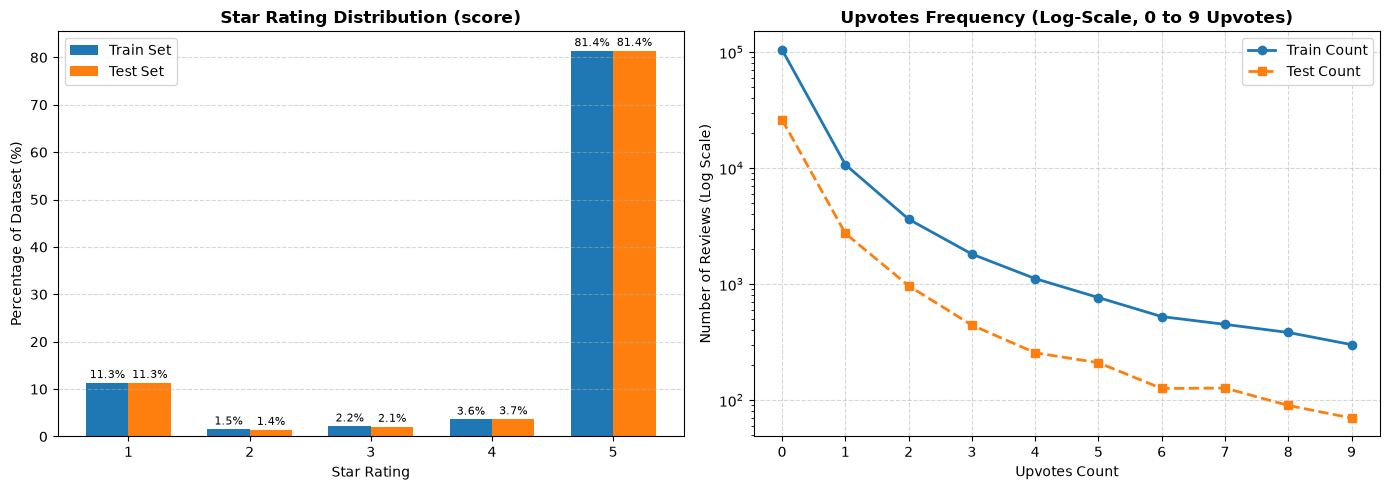

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scores = np.arange(1, 6)
width = 0.35

train_score_pct = df_train['score'].value_counts(normalize=True).sort_index() * 100
test_score_pct = df_test['score'].value_counts(normalize=True).sort_index() * 100

axes[0].bar(scores - width/2, train_score_pct, width, label='Train Set', color='#1f77b4')
axes[0].bar(scores + width/2, test_score_pct, width, label='Test Set', color='#ff7f0e')

axes[0].set_title('Star Rating Distribution (score)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Star Rating', fontsize=10)
axes[0].set_ylabel('Percentage of Dataset (%)', fontsize=10)
axes[0].set_xticks(scores)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend()

for i, s in enumerate(scores):
    axes[0].text(s - width/2, train_score_pct[s] + 1, f"{train_score_pct[s]:.1f}%", ha='center', fontsize=8)
    axes[0].text(s + width/2, test_score_pct[s] + 1, f"{test_score_pct[s]:.1f}%", ha='center', fontsize=8)

upvote_range = np.arange(0, 10)
train_upvote_counts = df_train['upvotes'].value_counts().reindex(upvote_range, fill_value=0)
test_upvote_counts = df_test['upvotes'].value_counts().reindex(upvote_range, fill_value=0)

axes[1].plot(upvote_range, train_upvote_counts.values, 'o-', label='Train Count', color='#1f77b4', linewidth=2)
axes[1].plot(upvote_range, test_upvote_counts.values, 's--', label='Test Count', color='#ff7f0e', linewidth=2)

axes[1].set_yscale('log')
axes[1].set_title('Upvotes Frequency (Log-Scale, 0 to 9 Upvotes)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Upvotes Count', fontsize=10)
axes[1].set_ylabel('Number of Reviews (Log Scale)', fontsize=10)
axes[1].set_xticks(upvote_range)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()


# Check missing values

In [8]:
def audit_missing_values(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    null_counts = df.isnull().sum()
    null_pcts = (null_counts / len(df)) * 100

    summary_df = pd.DataFrame({
        'Null Count': null_counts,
        'Null Percentage (%)': null_pcts.round(4)
    })

    print(f"=== Missing Value Audit: {split_name} ===")
    print(summary_df)
    print("-" * 45)
    return summary_df

_ = audit_missing_values(df_train, "Train Set")
_ = audit_missing_values(df_test, "Test Set")


=== Missing Value Audit: Train Set ===
         Null Count  Null Percentage (%)
content           3               0.0024
score             0               0.0000
upvotes           0               0.0000
---------------------------------------------
=== Missing Value Audit: Test Set ===
         Null Count  Null Percentage (%)
content           0                  0.0
score             0                  0.0
upvotes           0                  0.0
---------------------------------------------


Missing text may reflect rating-only submissions or collection errors

We distinguish missing text from empty strings, whitespace and non-text values. A row can look non-missing while still containing no usable review.

In [9]:
def inspect_text_validity(df: pd.DataFrame, split_name: str) -> None:
    total_rows = len(df)

    is_null = df['content'].isnull()

    non_string = df['content'].apply(lambda x: pd.notnull(x) and not isinstance(x, str))

    string_entries = df['content'].dropna().astype(str)

    exact_empty = (string_entries == "").sum()
    whitespace_only = string_entries.apply(lambda x: len(x) > 0 and len(x.strip()) == 0).sum()
    valid_text_count = total_rows - (is_null.sum() + exact_empty + whitespace_only + non_string.sum())

    print(f"=== Text Formatting Integrity: {split_name} ===")
    print(f"Total Rows              : {total_rows:,}")
    print(f"1. Standard NaN / Null  : {is_null.sum()}")
    print(f"2. Non-String Objects   : {non_string.sum()}")
    print(f"3. Exact Empty Strings  : {exact_empty}")
    print(f"4. Whitespace-Only Text : {whitespace_only}")
    print(f"Valid Text Entries      : {valid_text_count:,} ({(valid_text_count / total_rows) * 100:.2f}%)")
    print("-" * 50)

inspect_text_validity(df_train, "Train Set")
inspect_text_validity(df_test, "Test Set")


=== Text Formatting Integrity: Train Set ===
Total Rows              : 127,537
1. Standard NaN / Null  : 3
2. Non-String Objects   : 0
3. Exact Empty Strings  : 0
4. Whitespace-Only Text : 0
Valid Text Entries      : 127,534 (100.00%)
--------------------------------------------------
=== Text Formatting Integrity: Test Set ===
Total Rows              : 31,885
1. Standard NaN / Null  : 0
2. Non-String Objects   : 0
3. Exact Empty Strings  : 0
4. Whitespace-Only Text : 0
Valid Text Entries      : 31,885 (100.00%)
--------------------------------------------------


We inspect possible placeholders without automatically deleting them. Symbols such as “!” or “?” may be intentional feedback.

In [10]:
CANDIDATE_PLACEHOLDERS = ['null', 'n/a', 'na', 'none', 'nan', 'nil', '-', '.', '..', '...', '?', '!', 'no']

def inspect_suspicious_placeholders(df: pd.DataFrame, split_name: str) -> None:
    text_clean = df['content'].fillna('').astype(str).str.strip().str.lower()

    print(f"=== Placeholder Inspection: {split_name} ===")
    found_any = False

    for placeholder in CANDIDATE_PLACEHOLDERS:
        matches = df[text_clean == placeholder]
        match_count = len(matches)
        if match_count > 0:
            found_any = True
            print(f"Candidate '{placeholder}': {match_count} row(s)")
            score_dist = matches['score'].value_counts().to_dict()
            print(f"   └─ Score breakdown: {score_dist}")

    if not found_any:
        print("No suspicious candidate placeholders detected.")
    print("-" * 50)

inspect_suspicious_placeholders(df_train, "Train Set")
inspect_suspicious_placeholders(df_test, "Test Set")


=== Placeholder Inspection: Train Set ===
Candidate '.': 5 row(s)
   └─ Score breakdown: {5: 4, 1: 1}
Candidate '...': 3 row(s)
   └─ Score breakdown: {5: 2, 4: 1}
Candidate '?': 1 row(s)
   └─ Score breakdown: {2: 1}
--------------------------------------------------
=== Placeholder Inspection: Test Set ===
Candidate '.': 1 row(s)
   └─ Score breakdown: {4: 1}
Candidate '...': 1 row(s)
   └─ Score breakdown: {1: 1}
--------------------------------------------------


# Explore ratings and text

In [11]:
def audit_score_distribution(df: pd.DataFrame, split_name: str) -> pd.DataFrame:

    score_counts = df['score'].value_counts(dropna=False).sort_index()
    score_pcts = df['score'].value_counts(dropna=False, normalize=True).sort_index() * 100

    summary_df = pd.DataFrame({
        'Count': score_counts,
        'Percentage (%)': score_pcts.round(2)
    })

    invalid_mask = ~df['score'].isin([1, 2, 3, 4, 5]) | df['score'].isnull()
    invalid_count = invalid_mask.sum()

    print(f"=== Rating Score Audit: {split_name} ===")
    print(summary_df)
    print(f"Invalid / Out-of-Range Score Rows: {invalid_count}")
    print("-" * 45)
    return summary_df

_ = audit_score_distribution(df_train, "Train Set")
_ = audit_score_distribution(df_test, "Test Set")


=== Rating Score Audit: Train Set ===
        Count  Percentage (%)
score                        
1       14448           11.33
2        1948            1.53
3        2763            2.17
4        4600            3.61
5      103778           81.37
Invalid / Out-of-Range Score Rows: 0
---------------------------------------------
=== Rating Score Audit: Test Set ===
       Count  Percentage (%)
score                       
1       3618           11.35
2        461            1.45
3        670            2.10
4       1174            3.68
5      25962           81.42
Invalid / Out-of-Range Score Rows: 0
---------------------------------------------


In [12]:
for df in [df_train, df_test]:
    df['char_len'] = df['content'].fillna('').astype(str).str.len()
    df['word_count_approx'] = df['content'].fillna('').astype(str).str.split().str.len()

print("=== Train Set: Character Length Statistics ===")
print(df_train['char_len'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).round(2))

print("\n=== Train Set: Word Count Statistics (Approximate) ===")
print(df_train['word_count_approx'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).round(2))

print("\n=== Mean & Median Lengths by Star Rating (Train Set) ===")
length_by_score = df_train.groupby('score')[['char_len', 'word_count_approx']].agg(['mean', 'median', 'std']).round(2)
print(length_by_score)


=== Train Set: Character Length Statistics ===
count    127537.00
mean         30.39
std          51.82
min           0.00
5%            2.00
25%           5.00
50%          10.00
75%          34.00
95%         125.00
99%         252.00
max        1987.00
Name: char_len, dtype: float64

=== Train Set: Word Count Statistics (Approximate) ===
count    127537.00
mean          4.69
std           7.38
min           0.00
5%            1.00
25%           1.00
50%           2.00
75%           5.00
95%          18.00
99%          36.00
max         318.00
Name: word_count_approx, dtype: float64

=== Mean & Median Lengths by Star Rating (Train Set) ===
      char_len               word_count_approx              
          mean median    std              mean median    std
score                                                       
1        79.45   55.0  83.99             11.71    8.0  12.14
2        70.61   49.0  74.36             10.50    7.0  10.81
3        65.69   43.0  74.02              9.6

We use boxplots and log-length density curves to compare review lengths across ratings. Hidden boxplot outliers remain in the dataset.

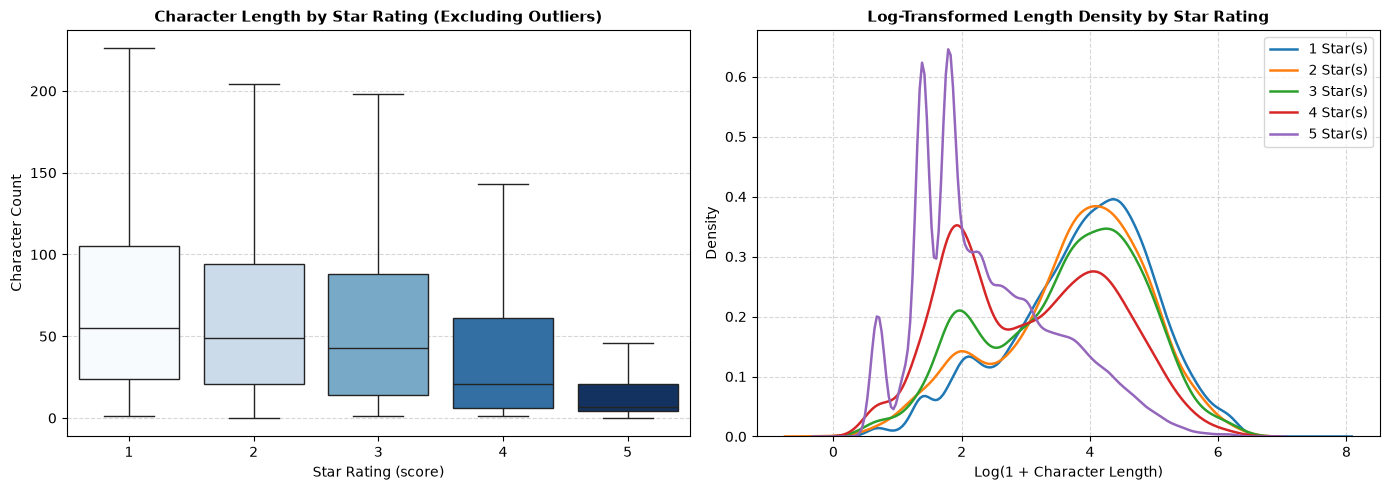

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    ax=axes[0],
    x='score',
    hue='score',
    legend=False,
    y='char_len',
    data=df_train,
    palette='Blues',
    showfliers=False
)
axes[0].set_title('Character Length by Star Rating (Excluding Outliers)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Star Rating (score)', fontsize=10)
axes[0].set_ylabel('Character Count', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

df_train['log_char_len'] = np.log1p(df_train['char_len'])

for score_val in range(1, 6):
    score_subset = df_train[df_train['score'] == score_val]['log_char_len']
    sns.kdeplot(
        ax=axes[1],
        data=score_subset,
        label=f'{score_val} Star(s)',
        linewidth=1.8
    )

axes[1].set_title('Log-Transformed Length Density by Star Rating', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Log(1 + Character Length)', fontsize=10)
axes[1].set_ylabel('Density', fontsize=10)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


We use regular expressions to flag emojis, repeated characters, links and Cyrillic text. These are approximate text-pattern checks, not reliable language identification.

In [14]:
EMOJI_PATTERN = re.compile(
    r'[\U0001F600-\U0001F64F'
    r'\U0001F300-\U0001F5FF'
    r'\U0001F680-\U0001F6FF'
    r'\U0001F1E0-\U0001F1FF'
    r'\U00002702-\U000027B0'
    r'\U000024C2-\U0001F251'
    r'\U0001F900-\U0001F9FF'
    r'\U0001FA70-\U0001FAFF'
    r'\U00002600-\U000026FF'
    r']+', flags=re.UNICODE
)

URL_PATTERN = re.compile(r'https?://\S+|www\.\S+')
REPEATED_CHAR_PATTERN = re.compile(r'(.)\1{2,}')
REPEATED_PUNCT_PATTERN = re.compile(r'([!?.]{2,})')
CYRILLIC_PATTERN = re.compile(r'[\u0400-\u04FF]')

def is_emoji_only(text: str) -> bool:
    if not text or not text.strip():
        return False
    stripped = text.strip()
    no_emojis = EMOJI_PATTERN.sub('', stripped).strip()
    return len(no_emojis) == 0 and len(stripped) > 0

def audit_text_patterns(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    texts = df['content'].fillna('').astype(str)
    total = len(df)

    counts = {
        'Very Short (<= 2 chars)': (texts.str.len() <= 2).sum(),
        'Very Long (> 300 chars)': (texts.str.len() > 300).sum(),
        'Emoji-Only Reviews'    : texts.apply(is_emoji_only).sum(),
        'Contains Links/URLs'   : texts.apply(lambda x: bool(URL_PATTERN.search(x))).sum(),
        'Repeated Chars (3+)'   : texts.apply(lambda x: bool(REPEATED_CHAR_PATTERN.search(x))).sum(),
        'Repeated Punctuation'  : texts.apply(lambda x: bool(REPEATED_PUNCT_PATTERN.search(x))).sum(),
        'Contains Cyrillic Text': texts.apply(lambda x: bool(CYRILLIC_PATTERN.search(x))).sum()
    }

    pattern_df = pd.DataFrame({
        'Count': list(counts.values()),
        'Percentage (%)': [(c / total * 100) for c in counts.values()]
    }, index=counts.keys()).round(2)

    print(f"=== Special Text Pattern Audit: {split_name} (Total: {total:,}) ===")
    print(pattern_df)
    print("-" * 55)
    return pattern_df

_ = audit_text_patterns(df_train, "Train Set")
_ = audit_text_patterns(df_test, "Test Set")


=== Special Text Pattern Audit: Train Set (Total: 127,537) ===
                         Count  Percentage (%)
Very Short (<= 2 chars)   8651            6.78
Very Long (> 300 chars)    817            0.64
Emoji-Only Reviews       10668            8.36
Contains Links/URLs          0            0.00
Repeated Chars (3+)       9613            7.54
Repeated Punctuation      3039            2.38
Contains Cyrillic Text     146            0.11
-------------------------------------------------------
=== Special Text Pattern Audit: Test Set (Total: 31,885) ===
                         Count  Percentage (%)
Very Short (<= 2 chars)   2087            6.55
Very Long (> 300 chars)    166            0.52
Emoji-Only Reviews        2619            8.21
Contains Links/URLs          0            0.00
Repeated Chars (3+)       2375            7.45
Repeated Punctuation       745            2.34
Contains Cyrillic Text      33            0.10
-------------------------------------------------------


In [15]:
SEED = 42

print(f"=== Stratified Sample Across Ratings (Seed = {SEED}) ===")
for score_val in range(1, 6):
    sample_row = df_train[df_train['score'] == score_val].sample(n=1, random_state=SEED).iloc[0]
    print(f"\n[Score = {sample_row['score']} Star(s) | Upvotes = {sample_row['upvotes']}]")
    print(f"Review Content: \"{sample_row['content']}\"")


=== Stratified Sample Across Ratings (Seed = 42) ===

[Score = 1 Star(s) | Upvotes = 0]
Review Content: "Boş şeydi"

[Score = 2 Star(s) | Upvotes = 0]
Review Content: "Karta pul gonderilerken hesaba cox gec oturur pul1-2 saat cekir birde arada programa daxil olmag olur duzelisler olsa yaxsi olardi"

[Score = 3 Star(s) | Upvotes = 0]
Review Content: "Əladır"

[Score = 4 Star(s) | Upvotes = 0]
Review Content: "daha sürətli olması istərdim"

[Score = 5 Star(s) | Upvotes = 0]
Review Content: "Əladı"


# Check duplicates

In [16]:
def audit_raw_duplicates(df: pd.DataFrame, split_name: str) -> None:
    total_rows = len(df)

    exact_row_dups = df.duplicated(subset=['content', 'score', 'upvotes'], keep='first').sum()

    text_dups = df.duplicated(subset=['content'], keep='first').sum()
    unique_texts = df['content'].nunique(dropna=False)

    print(f"=== Raw Duplicate Audit: {split_name} ===")
    print(f"Total Rows                     : {total_rows:,}")
    print(f"Exact Full-Row Duplicates     : {exact_row_dups:,} ({(exact_row_dups / total_rows) * 100:.2f}%)")
    print(f"Repeated Review Text Rows      : {text_dups:,} ({(text_dups / total_rows) * 100:.2f}%)")
    print(f"Unique Raw Review Texts        : {unique_texts:,}")
    print("-" * 55)

audit_raw_duplicates(df_train, "Train Set")
audit_raw_duplicates(df_test, "Test Set")


=== Raw Duplicate Audit: Train Set ===
Total Rows                     : 127,537
Exact Full-Row Duplicates     : 59,379 (46.56%)
Repeated Review Text Rows      : 62,850 (49.28%)
Unique Raw Review Texts        : 64,687
-------------------------------------------------------
=== Raw Duplicate Audit: Test Set ===
Total Rows                     : 31,885
Exact Full-Row Duplicates     : 13,297 (41.70%)
Repeated Review Text Rows      : 14,253 (44.70%)
Unique Raw Review Texts        : 17,632
-------------------------------------------------------


Repeated praise is not necessarily a collection error. Inspect repetition before deciding how to handle it.

We create a comparison key that ignores spacing and case differences, including Azerbaijani dotted and dotless I. The original review stays unchanged.

In [17]:
def create_norm_key(text: str) -> str:

    if not isinstance(text, str) or pd.isna(text):
        return ""

    text = unicodedata.normalize('NFKC', text)

    text = text.replace('İ', 'i').replace('I', 'ı').lower()

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df_train['norm_key'] = df_train['content'].apply(create_norm_key)
df_test['norm_key'] = df_test['content'].apply(create_norm_key)

print("Conservative comparison key ('norm_key') successfully created for Train and Test sets.")


Conservative comparison key ('norm_key') successfully created for Train and Test sets.


In [18]:
def audit_normalized_keys(df: pd.DataFrame, split_name: str) -> None:
    total_rows = len(df)
    raw_uniques = df['content'].nunique(dropna=False)
    norm_uniques = df['norm_key'].nunique()
    collapsed_count = raw_uniques - norm_uniques

    print(f"=== Normalized Key Audit: {split_name} ===")
    print(f"Unique Raw Content Strings    : {raw_uniques:,}")
    print(f"Unique Normalized Keys       : {norm_uniques:,}")
    print(f"Additional Text Variants Merged: {collapsed_count:,}")
    print("-" * 55)

audit_normalized_keys(df_train, "Train Set")
audit_normalized_keys(df_test, "Test Set")

print("=== Examples Collapsed ONLY After Normalization (Train Set) ===")

key_variant_counts = df_train[df_train['norm_key'] != ""].groupby('norm_key')['content'].nunique()
merged_keys = key_variant_counts[key_variant_counts > 1].index

for key in merged_keys[:5]:
    raw_variants = df_train[df_train['norm_key'] == key]['content'].unique().tolist()
    print(f"Normalized Key: \"{key}\"")
    print(f"  └─ Raw Variants: {raw_variants}")


=== Normalized Key Audit: Train Set ===
Unique Raw Content Strings    : 64,687
Unique Normalized Keys       : 62,843
Additional Text Variants Merged: 1,844
-------------------------------------------------------
=== Normalized Key Audit: Test Set ===
Unique Raw Content Strings    : 17,632
Unique Normalized Keys       : 17,118
Additional Text Variants Merged: 514
-------------------------------------------------------
=== Examples Collapsed ONLY After Normalization (Train Set) ===
Normalized Key: "(könüllü)"
  └─ Raw Variants: ['(könüllü)', '(KÖNÜLLÜ)']
Normalized Key: "(y)"
  └─ Raw Variants: ['(Y)', '(y)']
Normalized Key: ",ela"
  └─ Raw Variants: [',Ela', ',ela']
Normalized Key: "...super..."
  └─ Raw Variants: ['...Super...', '...super...']
Normalized Key: "5 ela"
  └─ Raw Variants: ['5 ela', '5 Ela']


We look for identical normalized texts with different ratings and for overlap between the original source splits. These checks reveal label ambiguity and potential evaluation leakage.

In [19]:
score_counts_per_key = df_train[df_train['norm_key'] != ""].groupby('norm_key')['score'].nunique()
conflicting_score_keys = score_counts_per_key[score_counts_per_key > 1]

print(f"=== Conflicting Target Score Audit (Train Set) ===")
print(f"Normalized keys associated with MULTIPLE different star ratings: {len(conflicting_score_keys):,}")

print("\nSample Conflicting Review Texts (Text -> Score Distribution):")
for key in conflicting_score_keys.index[:5]:
    subset = df_train[df_train['norm_key'] == key]
    dist = subset['score'].value_counts().to_dict()
    print(f"  Key: \"{key}\" -> Rating Breakdown: {dist} (Total Rows: {len(subset)})")

train_keys = set(df_train[df_train['norm_key'] != ""]['norm_key'])
test_keys = set(df_test[df_test['norm_key'] != ""]['norm_key'])
shared_keys = train_keys.intersection(test_keys)

train_shared_rows = df_train['norm_key'].isin(shared_keys).sum()
test_shared_rows = df_test['norm_key'].isin(shared_keys).sum()

print("\n=== Cross-Split Overlap Audit (Train vs. Test) ===")
print(f"Unique normalized keys appearing in BOTH Train and Test: {len(shared_keys):,}")
print(f"Train rows containing shared keys                      : {train_shared_rows:,} ({(train_shared_rows / len(df_train)) * 100:.2f}%)")
print(f"Test rows containing shared keys                       : {test_shared_rows:,} ({(test_shared_rows / len(df_test)) * 100:.2f}%)")


=== Conflicting Target Score Audit (Train Set) ===
Normalized keys associated with MULTIPLE different star ratings: 806

Sample Conflicting Review Texts (Text -> Score Distribution):
  Key: ",👍" -> Rating Breakdown: {5: 33, 2: 1} (Total Rows: 34)
  Key: "." -> Rating Breakdown: {5: 4, 1: 1} (Total Rows: 5)
  Key: ". ." -> Rating Breakdown: {5: 2, 3: 1} (Total Rows: 3)
  Key: "..." -> Rating Breakdown: {5: 2, 4: 1} (Total Rows: 3)
  Key: ":-)" -> Rating Breakdown: {5: 1, 3: 1, 2: 1} (Total Rows: 3)

=== Cross-Split Overlap Audit (Train vs. Test) ===
Unique normalized keys appearing in BOTH Train and Test: 2,196
Train rows containing shared keys                      : 63,531 (49.81%)
Test rows containing shared keys                       : 16,888 (52.97%)


Identical reviews can have different ratings

# Labeling data

We convert stars into three sentiment labels: 1–2 negative, 3 neutral and 4–5 positive.

In [20]:
def map_score_to_sentiment(score: int) -> str:

    if score in [1, 2]:
        return 'negative'
    elif score == 3:
        return 'neutral'
    elif score in [4, 5]:
        return 'positive'
    return np.nan

df_train['sentiment_label'] = df_train['score'].apply(map_score_to_sentiment)
df_test['sentiment_label'] = df_test['score'].apply(map_score_to_sentiment)

print("Sentiment labels ('sentiment_label') successfully added to Train and Test datasets.")


Sentiment labels ('sentiment_label') successfully added to Train and Test datasets.


In [21]:
def audit_sentiment_distribution(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    counts = df['sentiment_label'].value_counts(dropna=False)
    proportions = df['sentiment_label'].value_counts(dropna=False, normalize=True) * 100

    summary_df = pd.DataFrame({
        'Count': counts,
        'Proportion (%)': proportions.round(2)
    })

    print(f"=== Mapped Sentiment Class Distribution: {split_name} ===")
    print(summary_df)
    print("-" * 50)
    return summary_df

_ = audit_sentiment_distribution(df_train, "Train Set")
_ = audit_sentiment_distribution(df_test, "Test Set")


=== Mapped Sentiment Class Distribution: Train Set ===
                  Count  Proportion (%)
sentiment_label                        
positive         108378           84.98
negative          16396           12.86
neutral            2763            2.17
--------------------------------------------------
=== Mapped Sentiment Class Distribution: Test Set ===
                 Count  Proportion (%)
sentiment_label                       
positive         27136           85.11
negative          4079           12.79
neutral            670            2.10
--------------------------------------------------


We sample five reviews from each rating for a small label audit. This balanced sample helps inspect every rating but does not directly estimate the overall disagreement rate.

In [22]:
SEED = 42
SAMPLES_PER_RATING = 5

audit_samples = []

for rating_val in range(1, 6):
    sub_sample = df_train[df_train['score'] == rating_val].sample(
        n=SAMPLES_PER_RATING, random_state=SEED
    ).copy()
    audit_samples.append(sub_sample)

df_audit = pd.concat(audit_samples, ignore_index=True)

df_audit['text_sentiment'] = ""
df_audit['ambiguity_flag'] = False
df_audit['annotation_notes'] = ""

audit_columns = [
    'content', 'score', 'upvotes', 'sentiment_label',
    'text_sentiment', 'ambiguity_flag', 'annotation_notes'
]
df_audit = df_audit[audit_columns]

EXPORT_PATH = OUT / "manual_audit_candidates.csv"
if not Path(EXPORT_PATH).exists():
    df_audit.to_csv(EXPORT_PATH, index=False)
else:
    print('Existing human audit preserved:', EXPORT_PATH)

print(f"=== Exported Manual Audit Sample ===")
print(f"File Path    : {EXPORT_PATH}")
print(f"Sample Shape : {df_audit.shape[0]} rows × {df_audit.shape[1]} columns")
print("Breakdown by Rating Score:")
print(df_audit['score'].value_counts().sort_index().to_dict())

assistant_readings = [
    ('Əladır', 'positive', 'Praise: excellent; a 3-star label may disagree.'),
    ('Yaxsdi', 'positive', 'Informal praise: good; the sampled 2-star label disagrees.'),
    ('Kartlarimin balansi gostermir neyegore', 'negative', 'Complaint that card balances are not displayed; phrased as a question.'),
    ('Belə də', 'unclear', 'Roughly so-so; could be neutral or mildly negative.'),
    ('daha sürətli olması istərdim', 'mixed', 'Requests faster performance; does not express unambiguous overall dissatisfaction.'),
    ('🦋', 'unclear', 'A butterfly alone does not establish sentiment.'),
    ('👍', 'positive', 'Conventional approval emoji; context remains limited.'),
]
readings = pd.DataFrame(assistant_readings, columns=['content','assistant_suggested_sentiment','reason'])
readings['annotation_source'] = 'assistant interpretation; requires human verification'
matched_readings = df_audit[['content','score','sentiment_label']].merge(readings,on='content',how='inner')
display(matched_readings)
matched_readings.to_csv(OUT/'assistant_audit_examples.csv',index=False)
print('These illustrative judgments are not used to relabel the dataset.')


=== Exported Manual Audit Sample ===
File Path    : artifacts_corrected/20261102T200542515178Z/manual_audit_candidates.csv
Sample Shape : 25 rows × 7 columns
Breakdown by Rating Score:
{1: 5, 2: 5, 3: 5, 4: 5, 5: 5}


,content,score,sentiment_label,assistant_suggested_sentiment,reason,annotation_source
0,Yaxsdi,2,negative,positive,Informal praise: good; the sampled 2-star labe...,assistant interpretation; requires human verif...
1,Əladır,3,neutral,positive,Praise: excellent; a 3-star label may disagree.,assistant interpretation; requires human verif...
2,Kartlarimin balansi gostermir neyegore,3,neutral,negative,Complaint that card balances are not displayed...,assistant interpretation; requires human verif...
3,Belə də,3,neutral,unclear,Roughly so-so; could be neutral or mildly nega...,assistant interpretation; requires human verif...
4,daha sürətli olması istərdim,4,positive,mixed,Requests faster performance; does not express ...,assistant interpretation; requires human verif...
5,🦋,4,positive,unclear,A butterfly alone does not establish sentiment.,assistant interpretation; requires human verif...
6,👍,4,positive,positive,Conventional approval emoji; context remains l...,assistant interpretation; requires human verif...


These illustrative judgments are not used to relabel the dataset.


We attach assistant-proposed readings to the sampled texts for discussion. They are not verified human labels and do not replace the training targets.

In [23]:
AUDIT_READINGS = {'Boş şeydi': {'suggested_sentiment': 'negative', 'reason': 'Dismisses the service as useless.'}, 'son 2 gün ödəmələr keçmir': {'suggested_sentiment': 'negative', 'reason': 'Reports payments not going through for two days.'}, 'Bilmeden 3 hesab açdım deyə sipariş edə bilmirəm cındırlar': {'suggested_sentiment': 'negative', 'reason': 'Reports inability to order after accidentally creating multiple accounts; includes an insult.'}, 'Son zamanlar girmek cetinlesir xais edirem diqqet edesiniz': {'suggested_sentiment': 'negative', 'reason': 'Reports increasing difficulty logging in and requests attention.'}, 'Bugün işə gəlmək üçün bolt sifariş verdim sürücü ləğv etdi,bu hal bir neçə dəfə təkrar oldu,niyə bu cür sürücülərə görə işə gecikməli idim?': {'suggested_sentiment': 'negative', 'reason': 'Complains about repeated driver cancellations causing lateness.'}, 'Karta pul gonderilerken hesaba cox gec oturur pul1-2 saat cekir birde arada programa daxil olmag olur duzelisler olsa yaxsi olardi': {'suggested_sentiment': 'negative', 'reason': 'Complains about delayed transfers and access problems; requests fixes.'}, 'Bu nece acilir ne qeder eledim aca bilmedim deyir fin kod isteyir birde şifre ne olmalidir': {'suggested_sentiment': 'negative', 'reason': 'Reports failed attempts to open/access the app; also asks for help.'}, 'Yaxsdi': {'suggested_sentiment': 'positive', 'reason': 'Informal spelling of good; disagrees with the two-star rating.'}, 'Guncellemek olmur': {'suggested_sentiment': 'negative', 'reason': 'Reports inability to update.'}, 'Yaxşi deyil sadecə 1 pulsuz elan vermey olur evvel yaxşi idi indi hecnedi': {'suggested_sentiment': 'negative', 'reason': 'Says the app is not good and complains about the free-ad limit.'}, 'Əladır': {'suggested_sentiment': 'positive', 'reason': 'Excellent; disagrees with the three-star rating.'}, 'Kartlarimin balansi gostermir neyegore': {'suggested_sentiment': 'negative', 'reason': 'Reports missing card balances; complaint expressed as a question.'}, 'Belə də': {'suggested_sentiment': 'unclear', 'reason': 'So-so can express neutrality or mild dissatisfaction; context is insufficient.'}, 'Heçnə başa düşmədim nə üçündür bu praqramın nə özəliyi var?': {'suggested_sentiment': 'unclear', 'reason': 'Expresses confusion about the app purpose; could be informational or dissatisfied.'}, 'Yaxşı proqramdı ancaq mən sildikdən sonra yenidən yükləmək istədikdə axıra qədər yüklənib açılmadı. Yəni yüklənmədi.Bunun səbəbi nədir sizcə?': {'suggested_sentiment': 'mixed', 'reason': 'Initial praise followed by inability to reinstall/open the app.'}, 'daha sürətli olması istərdim': {'suggested_sentiment': 'mixed', 'reason': 'Requests faster performance without clear overall dissatisfaction.'}, 'Salam mende bu tetbiqde yazilir emeliyyatda seh buraxilib ne demekdi': {'suggested_sentiment': 'unclear', 'reason': 'Asks what a transaction error means; problem report without explicit overall sentiment.'}, '🦋': {'suggested_sentiment': 'unclear', 'reason': 'A butterfly emoji alone does not establish sentiment.'}, 'Super': {'suggested_sentiment': 'positive', 'reason': 'Explicit praise.'}, '👍': {'suggested_sentiment': 'positive', 'reason': 'Thumbs-up conventionally signals approval.'}, 'Əladı': {'suggested_sentiment': 'positive', 'reason': 'Excellent; informal spelling.'}, 'Ela👍': {'suggested_sentiment': 'positive', 'reason': 'Praise reinforced by thumbs-up.'}, 'Men kapital bank hesabimi elave edirem. kontur yuklemey isdirem u bank oz karti ile yukleyir onda ise pul yoxdur kapital kartina nece cevirim ve hesabima nezaret ede bilerem?': {'suggested_sentiment': 'unclear', 'reason': 'Asks how to switch funding cards and manage an account; no clear overall sentiment.'}, '😍': {'suggested_sentiment': 'positive', 'reason': 'Heart-eyes emoji conventionally expresses enthusiasm.'}}
reviewed_audit = df_audit[['content','score','sentiment_label']].copy()
reviewed_audit['assistant_suggested_sentiment'] = reviewed_audit.content.map(lambda t:AUDIT_READINGS.get(t,{}).get('suggested_sentiment','unreviewed'))
reviewed_audit['reason'] = reviewed_audit.content.map(lambda t:AUDIT_READINGS.get(t,{}).get('reason','New text: requires review.'))
reviewed_audit['annotation_source'] = 'assistant interpretation, not independently verified'
reviewed_audit['human_verified'] = False
reviewed_audit.to_csv(OUT/'assistant_reviewed_audit.csv',index=False)
display(reviewed_audit)
print('Labels were NOT changed. Do not calculate human agreement or population noise rates from these suggestions.')


,content,score,sentiment_label,assistant_suggested_sentiment,reason,annotation_source,human_verified
0,Boş şeydi,1,negative,negative,Dismisses the service as useless.,"assistant interpretation, not independently ve...",False
1,son 2 gün ödəmələr keçmir,1,negative,negative,Reports payments not going through for two days.,"assistant interpretation, not independently ve...",False
2,Bilmeden 3 hesab açdım deyə sipariş edə bilmir...,1,negative,negative,Reports inability to order after accidentally ...,"assistant interpretation, not independently ve...",False
3,Son zamanlar girmek cetinlesir xais edirem diq...,1,negative,negative,Reports increasing difficulty logging in and r...,"assistant interpretation, not independently ve...",False
4,Bugün işə gəlmək üçün bolt sifariş verdim sürü...,1,negative,negative,Complains about repeated driver cancellations ...,"assistant interpretation, not independently ve...",False
5,Karta pul gonderilerken hesaba cox gec oturur ...,2,negative,negative,Complains about delayed transfers and access p...,"assistant interpretation, not independently ve...",False
6,Bu nece acilir ne qeder eledim aca bilmedim de...,2,negative,negative,Reports failed attempts to open/access the app...,"assistant interpretation, not independently ve...",False
7,Yaxsdi,2,negative,positive,Informal spelling of good; disagrees with the ...,"assistant interpretation, not independently ve...",False
8,Guncellemek olmur,2,negative,negative,Reports inability to update.,"assistant interpretation, not independently ve...",False
9,Yaxşi deyil sadecə 1 pulsuz elan vermey olur e...,2,negative,negative,Says the app is not good and complains about t...,"assistant interpretation, not independently ve...",False


Labels were NOT changed. Do not calculate human agreement or population noise rates from these suggestions.


We search for praise in low-rated reviews and negative words in high-rated reviews. These are candidates for inspection: “Pis deyil” (“not bad”), for example, can fool a keyword rule.

In [24]:
NEG_KEYWORDS = ['bərbad', 'berbad', 'açılmır', 'acilmir', 'işləmir', 'islemir', 'pis']
POS_KEYWORDS = ['əla', 'ela', 'gözəl', 'gozel', 'süper', 'super', 'mükəmməl', 'mukemmel']

neg_pattern = r'\b(?:' + '|'.join(NEG_KEYWORDS) + r')\b'
pos_pattern = r'\b(?:' + '|'.join(POS_KEYWORDS) + r')\b'

content_clean = df_train['content'].fillna('').astype(str).str.lower()

high_score_neg_text = (df_train['score'].isin([4, 5])) & (content_clean.str.contains(neg_pattern, regex=True, na=False))

low_score_pos_text = (df_train['score'].isin([1, 2])) & (content_clean.str.contains(pos_pattern, regex=True, na=False))

print("=== Pattern-Based Heuristic Contradiction Check (Train Set) ===")
print(f"High Rating (4-5) + Negative Keyword : {high_score_neg_text.sum():,} rows")
print(f"Low Rating (1-2)  + Positive Keyword : {low_score_pos_text.sum():,} rows")

print("\n--- Sample: High Rating (5 Stars) with Negative Keywords ---")
print(df_train[high_score_neg_text][['content', 'score']].head(3).to_string(index=False))

print("\n--- Sample: Low Rating (1-2 Stars) with Positive Keywords ---")
print(df_train[low_score_pos_text][['content', 'score']].head(3).to_string(index=False))


=== Pattern-Based Heuristic Contradiction Check (Train Set) ===
High Rating (4-5) + Negative Keyword : 1,317 rows
Low Rating (1-2)  + Positive Keyword : 407 rows

--- Sample: High Rating (5 Stars) with Negative Keywords ---
                                                 content  score
                  Proqram yuklemiwem açılmır niye beledi      5
Birbank tedbiqiniz yaxsi islemir bu tedbiqe duzelis edin      5
                                               Pis deyil      5

--- Sample: Low Rating (1-2 Stars) with Positive Keywords ---
                                                                                              content  score
Bu proqram ço yaxşı proqramdı başqa proqaramlardan üsdün özeliyi ise bonus vermsidi süper proqramdı👍👍      1
                                                                                                Super      2
                                                                                                  Ela      1


# Clean text

Keep emojis, punctuation and negation. Normalize Unicode and whitespace; use Azerbaijani-aware casing for lexical analysis.

In [25]:
def preprocess_transformer_text(text: str) -> str:

    if not isinstance(text, str) or not text.strip():
        return np.nan

    text_str = str(text)

    text_str = unicodedata.normalize('NFKC', text_str)

    text_str = re.sub(r'\s+', ' ', text_str).strip()

    if not text_str:
        return np.nan

    return text_str

print("Transformer text preprocessing function ('preprocess_transformer_text') defined.")


Transformer text preprocessing function ('preprocess_transformer_text') defined.


We create separate text versions for the transformer and lexical models. The transformer keeps case, while the lexical version uses Azerbaijani-aware lowercase.

In [26]:
def az_lowercase(text: str) -> str:

    if pd.isna(text) or text is None:
        return np.nan
    return str(text).replace('İ', 'i').replace('I', 'ı').lower()

def preprocess_lexical_text(text: str) -> str:

    clean_text = preprocess_transformer_text(text)

    if pd.isna(clean_text):
        return np.nan

    return az_lowercase(clean_text)

df_train['text_transformer'] = df_train['content'].apply(preprocess_transformer_text)
df_train['text_lexical'] = df_train['content'].apply(preprocess_lexical_text)

df_test['text_transformer'] = df_test['content'].apply(preprocess_transformer_text)
df_test['text_lexical'] = df_test['content'].apply(preprocess_lexical_text)

print("Processed text columns ('text_transformer', 'text_lexical') added to Train and Test DataFrames.")


Processed text columns ('text_transformer', 'text_lexical') added to Train and Test DataFrames.


In [27]:
messy_indices = [0, 1, 351, 511, 731, 10319]

print("=== Side-by-Side Preprocessing Inspection ===")
for idx in messy_indices:
    raw_val = df_train.loc[idx, 'content']
    tr_val = df_train.loc[idx, 'text_transformer']
    lex_val = df_train.loc[idx, 'text_lexical']

    print(f"[Row Index {idx}]")
    print(f"  Raw ('content')         : {repr(raw_val)}")
    print(f"  Transformer-Ready       : {repr(tr_val)}")
    print(f"  Lexical (Lowercased)    : {repr(lex_val)}")
    print("-" * 60)


=== Side-by-Side Preprocessing Inspection ===
[Row Index 0]
  Raw ('content')         : 'Çox qəşəy'
  Transformer-Ready       : 'Çox qəşəy'
  Lexical (Lowercased)    : 'çox qəşəy'
------------------------------------------------------------
[Row Index 1]
  Raw ('content')         : 'Men niye nomre ile qeydiyatdan kece bilmirem......kecirem mesaj gelir ki Bu tetbiq işlemir....... islemirse niye camatin başin xarab edirsizz'
  Transformer-Ready       : 'Men niye nomre ile qeydiyatdan kece bilmirem......kecirem mesaj gelir ki Bu tetbiq işlemir....... islemirse niye camatin başin xarab edirsizz'
  Lexical (Lowercased)    : 'men niye nomre ile qeydiyatdan kece bilmirem......kecirem mesaj gelir ki bu tetbiq işlemir....... islemirse niye camatin başin xarab edirsizz'
------------------------------------------------------------
[Row Index 351]
  Raw ('content')         : 'Proqram yuklemiwem açılmır niye beledi'
  Transformer-Ready       : 'Proqram yuklemiwem açılmır niye beledi'
  Lexical (Low

We check that preprocessing preserved missing values and did not accidentally create literal “nan” text or empty strings.

In [28]:
def verify_preprocessing_integrity(df: pd.DataFrame, split_name: str) -> None:
    raw_nulls = df['content'].isnull().sum()
    tr_nulls = df['text_transformer'].isnull().sum()
    lex_nulls = df['text_lexical'].isnull().sum()

    tr_nan_strings = (df['text_transformer'].astype(str).str.lower() == 'nan').sum() - tr_nulls
    lex_nan_strings = (df['text_lexical'].astype(str).str.lower() == 'nan').sum() - lex_nulls

    valid_raw_df = df[df['content'].notnull()]
    tr_empty_from_valid = (valid_raw_df['text_transformer'] == "").sum()
    lex_empty_from_valid = (valid_raw_df['text_lexical'] == "").sum()

    print(f"=== Preprocessing Integrity Check: {split_name} ===")
    print(f"Total Rows                              : {len(df):,}")
    print(f"Raw Content Null Count                  : {raw_nulls}")
    print(f"Transformer Text Null Count             : {tr_nulls}")
    print(f"Lexical Text Null Count                 : {lex_nulls}")
    print(f"Literal 'nan' Strings Created           : Transformer={tr_nan_strings}, Lexical={lex_nan_strings}")
    print(f"Valid Raw Text Unexpectedly Emptied     : Transformer={tr_empty_from_valid}, Lexical={lex_empty_from_valid}")
    print("-" * 65)

verify_preprocessing_integrity(df_train, "Train Set")
verify_preprocessing_integrity(df_test, "Test Set")


=== Preprocessing Integrity Check: Train Set ===
Total Rows                              : 127,537
Raw Content Null Count                  : 3
Transformer Text Null Count             : 3
Lexical Text Null Count                 : 3
Literal 'nan' Strings Created           : Transformer=-3, Lexical=-3
Valid Raw Text Unexpectedly Emptied     : Transformer=0, Lexical=0
-----------------------------------------------------------------
=== Preprocessing Integrity Check: Test Set ===
Total Rows                              : 31,885
Raw Content Null Count                  : 0
Transformer Text Null Count             : 0
Lexical Text Null Count                 : 0
Literal 'nan' Strings Created           : Transformer=0, Lexical=0
Valid Raw Text Unexpectedly Emptied     : Transformer=0, Lexical=0
-----------------------------------------------------------------


# Create train, validation and test sets

Keep one row per normalized text and exclude groups with conflicting sentiment labels. This evaluates distinct, non-conflicting texts rather than the original distribution of all reviews.

We remove sentiment-conflicting text groups, keep one representative per remaining text, and create an 80/10/10 stratified split. Stratification keeps class proportions similar across the three partitions.

In [29]:
df_all_raw = pd.concat([
    df_train_raw.assign(original_split='train',source_row_id=['train:'+str(i) for i in range(len(df_train_raw))]),
    df_test_raw.assign(original_split='test',source_row_id=['test:'+str(i) for i in range(len(df_test_raw))])
],ignore_index=True)
df_all_raw['norm_key'] = df_all_raw.content.map(create_norm_key)
score_numeric = pd.to_numeric(df_all_raw.score,errors='coerce')
valid_text = df_all_raw.content.map(lambda x:isinstance(x,str) and bool(x.strip())) & df_all_raw.norm_key.ne('')
valid_score = score_numeric.isin([1,2,3,4,5])
df_all_raw['is_valid_for_sentiment'] = valid_text & valid_score
df_all_raw['sentiment_label'] = score_numeric.map(map_score_to_sentiment)
valid = df_all_raw.loc[df_all_raw.is_valid_for_sentiment].copy()
group_stats = valid.groupby('norm_key').agg(row_count=('norm_key','size'),sentiment_count=('sentiment_label','nunique'),score_count=('score','nunique'))
conflict_keys = set(group_stats.index[group_stats.sentiment_count.gt(1)])
conflicts = valid.loc[valid.norm_key.isin(conflict_keys)].copy()
conflicts.to_csv(OUT/'conflicting_sentiment_rows.csv',index=False)
print('Raw rows:',len(df_all_raw),'invalid text:',int((~valid_text).sum()),'invalid score:',int((~valid_score).sum()))
print('Conflicting sentiment groups:',len(conflict_keys),'affected rows:',len(conflicts))
display(valid.assign(conflicting=valid.norm_key.isin(conflict_keys)).groupby('sentiment_label').conflicting.agg(['mean','sum','count']))

df_all = valid.loc[~valid.norm_key.isin(conflict_keys)].sample(frac=1,random_state=SEED).drop_duplicates('norm_key').copy()
df_all['original_group_size'] = df_all.norm_key.map(group_stats.row_count)
df_all = df_all.sort_values('source_row_id').reset_index(drop=True)
train_idx,hold_idx = train_test_split(df_all.index,test_size=0.2,stratify=df_all.sentiment_label,random_state=SEED)
val_idx,test_idx = train_test_split(hold_idx,test_size=0.5,stratify=df_all.loc[hold_idx,'sentiment_label'],random_state=SEED)
df_all['partition'] = ''
df_all.loc[train_idx,'partition']='train'; df_all.loc[val_idx,'partition']='val'; df_all.loc[test_idx,'partition']='test'
assert df_all.norm_key.is_unique
print('Distinct non-conflicting texts retained:',len(df_all))
print('Rows collapsed after conflict removal:',len(valid)-len(conflicts)-len(df_all))


Raw rows: 159422 invalid text: 3 invalid score: 0
Conflicting sentiment groups: 657 affected rows: 68443


,mean,sum,count
sentiment_label,,,
negative,0.108479,2221,20474
neutral,0.201864,693,3433
positive,0.483566,65529,135512


Distinct non-conflicting texts retained: 77107
Rows collapsed after conflict removal: 13869


We compare the normalized-text keys across partitions and stop if any overlap remains. This prevents the same normalized review from appearing in both training and evaluation.

In [30]:
train_keys = set(df_all[df_all['partition'] == 'train']['norm_key'])
val_keys   = set(df_all[df_all['partition'] == 'val']['norm_key'])
test_keys  = set(df_all[df_all['partition'] == 'test']['norm_key'])

train_val_overlap  = len(train_keys.intersection(val_keys))
train_test_overlap = len(train_keys.intersection(test_keys))
val_test_overlap   = len(val_keys.intersection(test_keys))

print("=== Cross-Partition Leakage Verification ===")
print(f"Unique keys in Train Partition      : {len(train_keys):,}")
print(f"Unique keys in Validation Partition : {len(val_keys):,}")
print(f"Unique keys in Test Partition       : {len(test_keys):,}")
print("-" * 50)
print(f"Keys shared between Train & Validation : {train_val_overlap}")
print(f"Keys shared between Train & Test       : {train_test_overlap}")
print(f"Keys shared between Validation & Test  : {val_test_overlap}")

assert train_val_overlap == 0 and train_test_overlap == 0 and val_test_overlap == 0, \
    "Leakage detected! Duplicate keys cross partition boundaries."
print("\nPASSED: Zero cross-partition key overlap confirmed.")


=== Cross-Partition Leakage Verification ===
Unique keys in Train Partition      : 61,685
Unique keys in Validation Partition : 7,711
Unique keys in Test Partition       : 7,711
--------------------------------------------------
Keys shared between Train & Validation : 0
Keys shared between Train & Test       : 0
Keys shared between Validation & Test  : 0

PASSED: Zero cross-partition key overlap confirmed.


In [31]:
def audit_partitions(df: pd.DataFrame) -> pd.DataFrame:
    total_valid = len(df[df['partition'].notnull()])

    summary_rows = []
    for p in ['train', 'val', 'test']:
        p_df = df[df['partition'] == p]
        p_count = len(p_df)
        p_pct = (p_count / total_valid) * 100

        pos_pct = (p_df['sentiment_label'] == 'positive').mean() * 100
        neg_pct = (p_df['sentiment_label'] == 'negative').mean() * 100
        neu_pct = (p_df['sentiment_label'] == 'neutral').mean() * 100

        summary_rows.append({
            'Partition': p.capitalize(),
            'Row Count': f"{p_count:,}",
            'Share (%)': f"{p_pct:.2f}%",
            'Positive (%)': f"{pos_pct:.2f}%",
            'Negative (%)': f"{neg_pct:.2f}%",
            'Neutral (%)': f"{neu_pct:.2f}%"
        })

    summary_table = pd.DataFrame(summary_rows)
    print("=== Partition Sizes and Sentiment Class Distributions ===")
    print(summary_table.to_string(index=False))
    print("-" * 65)
    return summary_table

_ = audit_partitions(df_all)
for split,frame in df_all.groupby('partition'):
    print(split,'largest normalized-text share:',frame.norm_key.value_counts(normalize=True).max())
    assert frame.norm_key.value_counts().max()==1
    assert set(frame.sentiment_label)=={'negative','neutral','positive'}


=== Partition Sizes and Sentiment Class Distributions ===
Partition Row Count Share (%) Positive (%) Negative (%) Neutral (%)
    Train    61,685    80.00%       73.06%       23.39%       3.55%
      Val     7,711    10.00%       73.06%       23.40%       3.54%
     Test     7,711    10.00%       73.05%       23.40%       3.55%
-----------------------------------------------------------------
test largest normalized-text share: 0.00012968486577616392
train largest normalized-text share: 1.621139661181811e-05
val largest normalized-text share: 0.00012968486577616392


We select up to 25,000 training reviews while preserving class proportions. This limits training time and gives both classifiers the same training examples.

In [32]:
CAPPED_SIZE = 25000
df_train_full = df_all.loc[df_all.partition.eq('train')].copy()
if len(df_train_full)>CAPPED_SIZE:
    _,df_train_capped = train_test_split(df_train_full,test_size=CAPPED_SIZE,stratify=df_train_full.sentiment_label,random_state=SEED)
else:
    df_train_capped = df_train_full.copy()
display(pd.DataFrame({'full_train_count':df_train_full.sentiment_label.value_counts(),'used_train_count':df_train_capped.sentiment_label.value_counts(),'full_train_share':df_train_full.sentiment_label.value_counts(normalize=True),'used_train_share':df_train_capped.sentiment_label.value_counts(normalize=True)}))


,full_train_count,used_train_count,full_train_share,used_train_share
sentiment_label,,,,
positive,45065,18264,0.730567,0.73056
negative,14430,5848,0.233930,0.23392
neutral,2190,888,0.035503,0.03552


We save the selected row IDs, partitions and preparation settings. These records make it possible to trace which data was used in the experiment.

In [33]:
manifest_df = df_all[['source_row_id','partition','norm_key','score','sentiment_label','original_split','original_group_size']].copy()
manifest_df.to_csv(OUT/'partition_manifest.csv',index=False)
df_train_capped[['source_row_id','norm_key','sentiment_label']].to_csv(OUT/'actual_training_rows.csv',index=False)
config_metadata = {'seed':SEED,'policy':'one row per normalized key; exclude conflicting sentiment keys','raw_rows':len(df_all_raw),'conflicting_keys':len(conflict_keys),'conflicting_rows':len(conflicts),'retained_unique_texts':len(df_all),'partition_counts':df_all.partition.value_counts().to_dict(),'training_rows':len(df_train_capped)}
(OUT/'partition_config.json').write_text(json.dumps(config_metadata,indent=2))
print('New manifests saved under',OUT)


New manifests saved under artifacts_corrected/20261102T200542515178Z


# Train baseline models

Both classifiers use the same 25,000 training examples. Select the baseline using validation macro-F1.

In [34]:
def preprocess_transformer_text(text):
    if not isinstance(text, str) or not text.strip():
        return np.nan
    text_str = str(text)
    text_str = unicodedata.normalize('NFKC', text_str)
    text_str = re.sub(r'\s+', ' ', text_str).strip()
    return text_str if text_str else np.nan

def az_lowercase(text):
    if not isinstance(text, str) or not text.strip():
        return np.nan
    return str(text).replace('İ', 'i').replace('I', 'ı').lower()

def preprocess_lexical_text(text):
    clean_text = preprocess_transformer_text(text)
    if pd.isna(clean_text):
        return np.nan
    return az_lowercase(clean_text)

df_all['text_transformer'] = df_all['content'].apply(preprocess_transformer_text)
df_all['text_lexical'] = df_all['content'].apply(preprocess_lexical_text)

print("Columns successfully verified/added to df_all:")
print([col for col in ['content', 'text_transformer', 'text_lexical'] if col in df_all.columns])

train_df_sub = df_all.loc[df_train_capped.index].copy()
val_df_sub = df_all.loc[df_all.partition.eq('val')].copy()
test_df_sub = df_all.loc[df_all.partition.eq('test')].copy()
assert train_df_sub.text_transformer.notna().all()
assert all(set(f.sentiment_label) == {'negative','neutral','positive'} for f in [train_df_sub,val_df_sub,test_df_sub])


Columns successfully verified/added to df_all:
['content', 'text_transformer', 'text_lexical']


We first predict the most common training class for every review. This shows how much accuracy is possible without learning anything from the text.

In [35]:
train_mask = (df_all['partition'] == 'train') & (df_all['is_valid_for_sentiment'])
val_mask = (df_all['partition'] == 'val') & (df_all['is_valid_for_sentiment'])

X_train = train_df_sub['text_lexical']
y_train = train_df_sub['sentiment_label']

X_val = df_all.loc[val_mask, 'text_lexical'].fillna('')
y_val = df_all.loc[val_mask, 'sentiment_label']

dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

y_val_dummy = dummy_clf.predict(X_val)

print("=== Majority-Class Dummy Predictor (Validation Set) ===")
print(f"Accuracy        : {accuracy_score(y_val, y_val_dummy):.4f}")
print(f"Macro F1-Score  : {f1_score(y_val, y_val_dummy, average='macro'):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_val_dummy, zero_division=0))


=== Majority-Class Dummy Predictor (Validation Set) ===
Accuracy        : 0.7306
Macro F1-Score  : 0.2815

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00      1804
     neutral       0.00      0.00      0.00       273
    positive       0.73      1.00      0.84      5634

    accuracy                           0.73      7711
   macro avg       0.24      0.33      0.28      7711
weighted avg       0.53      0.73      0.62      7711



We connect TF-IDF and logistic regression in a scikit-learn pipeline. TF-IDF turns text into numeric features; logistic regression learns how those features relate to sentiment.

In [36]:
def create_baseline_pipeline(
    ngram_range=(1, 2),
    analyzer='word',
    max_features=25000,
    class_weight='balanced',
    C=1.0,
    random_state=42
):

    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer=analyzer,
            ngram_range=ngram_range,
            max_features=max_features,
            sublinear_tf=True
        )),
        ('clf', LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=1000,
            random_state=random_state
        ))
    ])
    return pipeline

print("Baseline TF-IDF + Logistic Regression pipeline builder initialized.")


Baseline TF-IDF + Logistic Regression pipeline builder initialized.


We compare word and character features, class weighting and regularization using validation macro-F1. Character fragments can help with informal spelling, while macro-F1 gives each class equal importance.

In [37]:
def create_baseline_pipeline(
    ngram_range=(1, 2),
    analyzer='word',
    max_features=25000,
    class_weight='balanced',
    C=1.0,
    random_state=42
):

    return Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer=analyzer,
            ngram_range=ngram_range,
            max_features=max_features,
            sublinear_tf=True
        )),
        ('clf', LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=1000,
            random_state=random_state
        ))
    ])

configurations = [
    {
        'name': 'Config 1: Word (1,2) Unbalanced',
        'analyzer': 'word',
        'ngram_range': (1, 2),
        'max_features': 25000,
        'class_weight': None,
        'C': 1.0
    },
    {
        'name': 'Config 2: Word (1,2) Balanced',
        'analyzer': 'word',
        'ngram_range': (1, 2),
        'max_features': 25000,
        'class_weight': 'balanced',
        'C': 1.0
    },
    {
        'name': 'Config 3: Char_wb (3,5) Balanced',
        'analyzer': 'char_wb',
        'ngram_range': (3, 5),
        'max_features': 50000,
        'class_weight': 'balanced',
        'C': 1.0
    },
    {
        'name': 'Config 4: Char_wb (3,5) Balanced (C=2.0)',
        'analyzer': 'char_wb',
        'ngram_range': (3, 5),
        'max_features': 50000,
        'class_weight': 'balanced',
        'C': 2.0
    }
]

results = []
fitted_models = {}

print("=== Running Baseline Model Comparison (Validation Split) ===")
for cfg in configurations:
    model = create_baseline_pipeline(
        ngram_range=cfg['ngram_range'],
        analyzer=cfg['analyzer'],
        max_features=cfg['max_features'],
        class_weight=cfg['class_weight'],
        C=cfg['C']
    )

    model.fit(X_train, y_train)

    preds_val = model.predict(X_val)

    val_acc = accuracy_score(y_val, preds_val)
    val_macro_f1 = f1_score(y_val, preds_val, average='macro')
    val_weighted_f1 = f1_score(y_val, preds_val, average='weighted')

    results.append({
        'Model Configuration': cfg['name'],
        'Val Accuracy': val_acc,
        'Val Macro F1': val_macro_f1,
        'Val Weighted F1': val_weighted_f1
    })

    fitted_models[cfg['name']] = model

results_df = pd.DataFrame(results).sort_values(by='Val Macro F1', ascending=False)
print(results_df.to_string(index=False))


=== Running Baseline Model Comparison (Validation Split) ===
                     Model Configuration  Val Accuracy  Val Macro F1  Val Weighted F1
Config 4: Char_wb (3,5) Balanced (C=2.0)      0.785501      0.568184         0.806382
        Config 3: Char_wb (3,5) Balanced      0.772144      0.562675         0.798800
           Config 2: Word (1,2) Balanced      0.780184      0.559985         0.800887
         Config 1: Word (1,2) Unbalanced      0.831799      0.521644         0.812182


We inspect the selected baseline with per-class metrics and a normalized confusion matrix. Each row shows where reviews of one true class are being predicted.

=== Detailed Evaluation: Config 4: Char_wb (3,5) Balanced (C=2.0) ===
              precision    recall  f1-score   support

    negative     0.6443    0.7672    0.7004      1804
     neutral     0.0941    0.2161    0.1311       273
    positive     0.9348    0.8190    0.8730      5634

    accuracy                         0.7855      7711
   macro avg     0.5577    0.6008    0.5682      7711
weighted avg     0.8371    0.7855    0.8064      7711



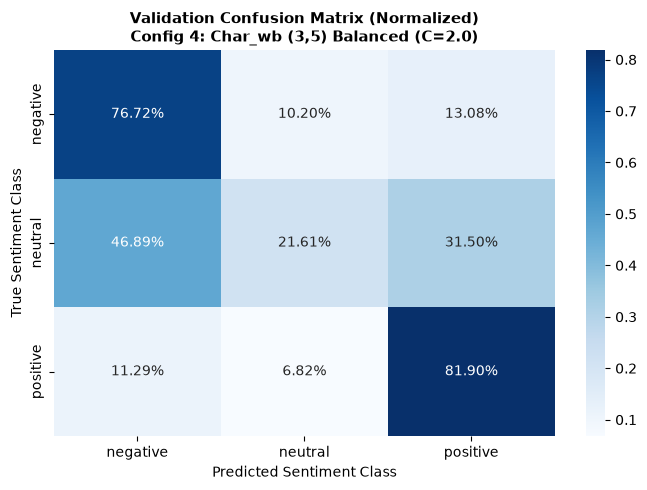

In [38]:
best_model_name = results_df.iloc[0]['Model Configuration']
best_model = fitted_models[best_model_name]

y_val_pred = best_model.predict(X_val)

labels = ['negative', 'neutral', 'positive']

print(f"=== Detailed Evaluation: {best_model_name} ===")
print(classification_report(y_val, y_val_pred, target_names=labels, digits=4))

cm = confusion_matrix(y_val, y_val_pred, labels=labels, normalize='true')

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f'Validation Confusion Matrix (Normalized)\n{best_model_name}', fontsize=11, fontweight='bold')
plt.xlabel('Predicted Sentiment Class', fontsize=10)
plt.ylabel('True Sentiment Class', fontsize=10)
plt.tight_layout()
plt.show()


# Prepare transformer inputs

We load XLM-R’s pretrained tokenizer so reviews use the same vocabulary as the model.

In [39]:
if RUN_TRANSFORMER:
    MODEL_NAME = "xlm-roberta-base"

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    print(f"=== Loaded Tokenizer: {MODEL_NAME} ===")
    print(f"Vocabulary Size       : {tokenizer.vocab_size:,} tokens")
    print(f"BOS (Beginning) Token : {tokenizer.bos_token} (ID: {tokenizer.bos_token_id})")
    print(f"EOS (End) Token       : {tokenizer.eos_token} (ID: {tokenizer.eos_token_id})")
    print(f"PAD Token             : {tokenizer.pad_token} (ID: {tokenizer.pad_token_id})")
    print(f"UNK Token             : {tokenizer.unk_token} (ID: {tokenizer.unk_token_id})")
else:
    print("Transformer preparation skipped: RUN_TRANSFORMER=False")


=== Loaded Tokenizer: xlm-roberta-base ===
Vocabulary Size       : 250,002 tokens
BOS (Beginning) Token : <s> (ID: 0)
EOS (End) Token       : </s> (ID: 2)
PAD Token             : <pad> (ID: 1)
UNK Token             : <unk> (ID: 3)


We inspect how the tokenizer splits standard text, informal spelling, emojis and mixed-language reviews into smaller units.

In [40]:
if RUN_TRANSFORMER:
    test_phrases = {
        "Standard Azerbaijani" : "Mükəmməl xidmət üçün təşəkkürlər, tətbiqi yükləmişəm.",
        "Informal / Phonetic"  : "yuklemiwem islemir acilmir hec cur",
        "Emoji-Heavy Review"   : "Əla tətbiqdir 👍👍❤️❤️",
        "Code-Switched Review" : "Приложение супер ama cox donur, error verir"
    }

    print("=== Subword Segmentation Breakdown (XLM-RoBERTa Tokenizer) ===")
    for category, phrase in test_phrases.items():

        subwords = tokenizer.tokenize(phrase)

        input_ids = tokenizer.encode(phrase, add_special_tokens=True)

        print(f"\n[{category}]")
        print(f"  Raw Text    : \"{phrase}\"")
        print(f"  Subwords    : {subwords}")
        print(f"  Token Count : {len(subwords)} subwords (Input ID Length: {len(input_ids)})")
else:
    print("Transformer preparation skipped: RUN_TRANSFORMER=False")


=== Subword Segmentation Breakdown (XLM-RoBERTa Tokenizer) ===

[Standard Azerbaijani]
  Raw Text    : "Mükəmməl xidmət üçün təşəkkürlər, tətbiqi yükləmişəm."
  Subwords    : ['▁Mü', 'k', 'əm', 'mə', 'l', '▁xidmət', '▁üçün', '▁təşəkkür', 'lər', ',', '▁tətbiqi', '▁yüklə', 'mişəm', '.']
  Token Count : 14 subwords (Input ID Length: 16)

[Informal / Phonetic]
  Raw Text    : "yuklemiwem islemir acilmir hec cur"
  Subwords    : ['▁yuk', 'le', 'mi', 'we', 'm', '▁is', 'le', 'mir', '▁a', 'cil', 'mir', '▁he', 'c', '▁cur']
  Token Count : 14 subwords (Input ID Length: 16)

[Emoji-Heavy Review]
  Raw Text    : "Əla tətbiqdir 👍👍❤️❤️"
  Subwords    : ['▁Əl', 'a', '▁tətbiq', 'dir', '▁', '👍', '👍', '❤', '️', '❤', '️']
  Token Count : 11 subwords (Input ID Length: 13)

[Code-Switched Review]
  Raw Text    : "Приложение супер ama cox donur, error verir"
  Subwords    : ['▁Приложение', '▁супер', '▁ama', '▁co', 'x', '▁do', 'nur', ',', '▁error', '▁verir']
  Token Count : 10 subwords (Input ID Length: 12)


In [41]:
if RUN_TRANSFORMER:

    SAMPLE_SIZE = 10000
    train_sample_texts = df_all[
        (df_all['partition'] == 'train') & (df_all['is_valid_for_sentiment'])
    ]['text_transformer'].dropna().sample(n=min(SAMPLE_SIZE, len(df_train_full)), random_state=42).tolist()

    token_lengths = [
        len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
        for text in train_sample_texts
    ]

    token_series = pd.Series(token_lengths)

    print(f"=== Subword Sequence Length Distribution (N = {SAMPLE_SIZE:,} Training Reviews) ===")
    print(f"Mean Token Length   : {token_series.mean():.2f}")
    print(f"Median Token Length : {token_series.median():.2f}")
    print(f"Std Deviation       : {token_series.std():.2f}")
    print(f"Min Token Length    : {token_series.min()}")
    print(f"Max Token Length    : {token_series.max()}")
    print("\nSubword Length Percentiles:")
    for p in [50, 75, 90, 95, 98, 99, 99.9]:
        val = np.percentile(token_series, p)
        print(f"  {p:>4}th Percentile : {val:.1f} subwords")
else:
    print("Transformer preparation skipped: RUN_TRANSFORMER=False")


=== Subword Sequence Length Distribution (N = 10,000 Training Reviews) ===
Mean Token Length   : 18.87
Median Token Length : 13.00
Std Deviation       : 18.92
Min Token Length    : 3
Max Token Length    : 439

Subword Length Percentiles:
    50th Percentile : 13.0 subwords
    75th Percentile : 23.0 subwords
    90th Percentile : 39.0 subwords
    95th Percentile : 52.0 subwords
    98th Percentile : 78.0 subwords
    99th Percentile : 96.0 subwords
  99.9th Percentile : 154.0 subwords


We estimate how many sampled reviews would be shortened at each token limit. This makes the trade-off between retained context and memory use visible.

In [42]:
if RUN_TRANSFORMER:
    CANDIDATE_MAX_LENGTHS = [32, 64, 128, 256, 512]

    print("=== Sequence Truncation Rate Analysis ===")
    print(f"Total Sampled Reviews: {len(token_series):,}\n")

    for max_len in CANDIDATE_MAX_LENGTHS:
        truncated_count = int((token_series > max_len).sum())
        truncation_rate = (truncated_count / len(token_series)) * 100
        retention_rate = 100.0 - truncation_rate

        print(f"Max Length = {max_len:>3} | Retained: {retention_rate:>6.2f}% | Truncated: {truncated_count:>5,} reviews ({truncation_rate:>5.2f}%)")

    print("-" * 70)
else:
    print("Transformer preparation skipped: RUN_TRANSFORMER=False")


=== Sequence Truncation Rate Analysis ===
Total Sampled Reviews: 10,000

Max Length =  32 | Retained:  86.29% | Truncated: 1,371 reviews (13.71%)
Max Length =  64 | Retained:  97.10% | Truncated:   290 reviews ( 2.90%)
Max Length = 128 | Retained:  99.59% | Truncated:    41 reviews ( 0.41%)
Max Length = 256 | Retained:  99.98% | Truncated:     2 reviews ( 0.02%)
Max Length = 512 | Retained: 100.00% | Truncated:     0 reviews ( 0.00%)
----------------------------------------------------------------------


In [43]:
if RUN_TRANSFORMER:

    LABEL2ID = {'negative': 0, 'neutral': 1, 'positive': 2}
    ID2LABEL = {0: 'negative', 1: 'neutral', 2: 'positive'}

    class AppReviewTransformerDataset(Dataset):

        def __init__(self, texts, labels, tokenizer, max_length=128):
            self.texts = list(texts)
            self.labels = [LABEL2ID[lbl] for lbl in labels]
            self.tokenizer = tokenizer
            self.max_length = max_length

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            text = str(self.texts[idx])
            label = self.labels[idx]

            encoding = self.tokenizer(
                text,
                truncation=True,
                max_length=self.max_length,
                add_special_tokens=True,
                return_attention_mask=True
            )

            return {
                'input_ids': encoding['input_ids'],
                'attention_mask': encoding['attention_mask'],
                'labels': label
            }

    print("AppReviewTransformerDataset class successfully defined.")
else:
    print("Transformer preparation skipped: RUN_TRANSFORMER=False")


AppReviewTransformerDataset class successfully defined.


We use Hugging Face Datasets to tokenize the splits and a padding collator to build batches. Reviews are capped at 128 tokens and padded only to the longest sequence in each batch.

In [44]:
if RUN_TRANSFORMER:
    from datasets import Dataset as HFDataset
    def encode_frame(frame):
        ds = HFDataset.from_dict({'text':frame.text_transformer.tolist(), 'labels':frame.sentiment_label.map(LABEL2ID).tolist()})
        return ds.map(lambda batch: tokenizer(batch['text'], truncation=True, max_length=128), batched=True, remove_columns=['text'])
    train_dataset = encode_frame(train_df_sub)
    val_dataset = encode_frame(val_df_sub)
    test_dataset = encode_frame(test_df_sub)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    first_batch = data_collator([train_dataset[0]])
    print({k:tuple(v.shape) for k,v in first_batch.items()})
    print(tokenizer.decode(first_batch['input_ids'][0], skip_special_tokens=True))
    assert first_batch['labels'].min() >= 0 and first_batch['labels'].max() <= 2
else:
    print('Transformer datasets skipped.')


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7711 [00:00<?, ? examples/s]

Map:   0%|          | 0/7711 [00:00<?, ? examples/s]

{'labels': (1,), 'input_ids': (1, 15), 'attention_mask': (1, 15)}
Gözəl di ama həmisəlik olsa daha gozəl olar


# Train XLM-R

Use batch size 1, gradient accumulation and checkpointing to reduce GPU memory use. The loss check verifies that class weights remain effective; validation macro-F1 selects the checkpoint.

We calculate class weights from the actual training sample and verify that they still affect one-review batches. A forward/backward smoke test checks the model before the full training run.

In [45]:
LABEL2ID = {'negative':0, 'neutral':1, 'positive':2}
ID2LABEL = {v:k for k,v in LABEL2ID.items()}
LABELS = list(LABEL2ID)
EPOCHS, BATCH_SIZE, ACCUMULATION, LR = 3, 1, 32, 2e-5
training_history = []
transformer_model = None
if RUN_TRANSFORMER:
    weights = compute_class_weight('balanced', classes=np.arange(3), y=train_df_sub.sentiment_label.map(LABEL2ID))
    class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
    def fresh_model():
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=3,
            id2label=ID2LABEL,
            label2id=LABEL2ID,
        )
        model.gradient_checkpointing_enable()
        model.config.use_cache = False
        return model.to(DEVICE)
    def make_loader(dataset, shuffle=False):
        return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=data_collator, generator=torch.Generator().manual_seed(SEED))
    def criterion(logits, targets):
        return torch.nn.functional.cross_entropy(logits, targets, weight=class_weights, reduction='none').mean()

    probe_logits = torch.zeros((1,3),device=DEVICE)
    for target_id in range(3):
        target = torch.tensor([target_id],device=DEVICE)
        unweighted = torch.nn.functional.cross_entropy(probe_logits,target)
        assert torch.allclose(criterion(probe_logits,target),unweighted*class_weights[target_id])
    print('Verified: singleton losses preserve class weights:',class_weights.tolist())
    smoke = fresh_model()
    smoke.train()
    batch = {k:v.to(DEVICE) for k,v in first_batch.items()}
    logits = smoke(**{k:v for k,v in batch.items() if k!='labels'}).logits
    loss = criterion(logits, batch['labels'])
    assert torch.isfinite(loss)
    loss.backward()
    print('Smoke-test loss:', loss.item())
    del smoke, batch, logits, loss
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print('NOT RUN: transformer smoke test and training.')


Verified: singleton losses preserve class weights: [1.4249886274337769, 9.384384155273438, 0.4562709927558899]


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Smoke-test loss: 0.46980780363082886


We fine-tune XLM-R with AdamW and a warmup/decay learning-rate schedule, accumulating gradients over 32 batches. After each epoch, we measure validation macro-F1 and save the best checkpoint for final evaluation.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3:   0%|          | 0/25000 [00:00<?, ?batch/s]

Predicting:   0%|          | 0/7711 [00:00<?, ?batch/s]

{'epoch': 1, 'train_loss': 0.9854112850804627, 'val_macro_f1': 0.5403264325561753}
Validation predicted class counts: {'negative': 2799, 'neutral': 335, 'positive': 4577}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

Epoch 3/3:   0%|          | 0/25000 [00:00<?, ?batch/s]

Predicting:   0%|          | 0/7711 [00:00<?, ?batch/s]

{'epoch': 3, 'train_loss': 0.7573483450569958, 'val_macro_f1': 0.5781416471499919}
Validation predicted class counts: {'negative': 1984, 'neutral': 1112, 'positive': 4615}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

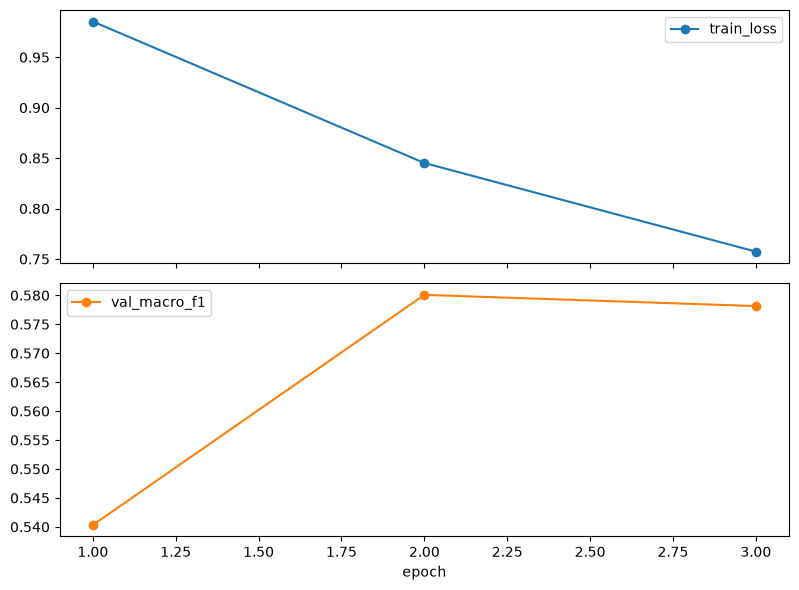

In [46]:
def predict_transformer(model, dataset):
    model.eval()
    predictions = []
    with torch.no_grad():
        for batch in tqdm(make_loader(dataset), desc='Predicting', unit='batch'):
            inputs = {k:v.to(DEVICE) for k,v in batch.items() if k!='labels'}
            predictions.extend(model(**inputs).logits.argmax(-1).cpu().tolist())
    return np.asarray(predictions)

if RUN_TRANSFORMER:
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    transformer_model = fresh_model()
    optimizer = AdamW(transformer_model.parameters(), lr=LR, weight_decay=0.01)
    loader = make_loader(train_dataset, shuffle=True)
    updates = math.ceil(len(loader)/ACCUMULATION)*EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1*updates), num_training_steps=updates)
    best_f1 = -1.0
    for epoch in range(EPOCHS):
        transformer_model.train(); optimizer.zero_grad(); total_loss = 0.0
        for step,batch in enumerate(tqdm(loader, desc=f'Epoch {epoch+1}/{EPOCHS}', unit='batch')):
            batch = {k:v.to(DEVICE) for k,v in batch.items()}
            logits = transformer_model(**{k:v for k,v in batch.items() if k!='labels'}).logits
            raw_loss = criterion(logits, batch['labels'])

            window_size = min(ACCUMULATION, len(loader)-(step//ACCUMULATION)*ACCUMULATION)
            (raw_loss/window_size).backward()
            total_loss += raw_loss.item()
            if (step+1)%ACCUMULATION==0 or step+1==len(loader):
                torch.nn.utils.clip_grad_norm_(transformer_model.parameters(),1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
        pred = predict_transformer(transformer_model,val_dataset)
        score = f1_score(val_df_sub.sentiment_label.map(LABEL2ID),pred,labels=[0,1,2],average='macro',zero_division=0)
        row = {'epoch':epoch+1,'train_loss':total_loss/len(loader),'val_macro_f1':score}
        training_history.append(row); print(row)
        print('Validation predicted class counts:',dict(zip(LABELS,np.bincount(pred,minlength=3).tolist())))
        if score > best_f1:
            best_f1 = score
            transformer_model.save_pretrained(OUT/'sentiment_xlmr')
            tokenizer.save_pretrained(OUT/'sentiment_xlmr')
    del optimizer, scheduler, transformer_model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    transformer_model = AutoModelForSequenceClassification.from_pretrained(OUT/'sentiment_xlmr').to(DEVICE)
    history = pd.DataFrame(training_history)
    history.to_csv(OUT/'training_history.csv',index=False)
    history.plot(x='epoch',y=['train_loss','val_macro_f1'],subplots=True,marker='o',figsize=(8,6)); plt.tight_layout(); plt.show()
else:
    print('Transformer checkpoint not trained or evaluated in this run.')


# Evaluate models

Compare models on the same test set. Per-class scores show weaknesses that accuracy can hide.

We evaluate every selected model on the same test reviews and save its predictions. Accuracy, macro-F1 and class-level reports show different aspects of performance.

majority prediction counts: {'negative': 0, 'neutral': 0, 'positive': 7711}


,precision,recall,f1-score,support
negative,0.000000,0.000000,0.000000,1804.000000
neutral,0.000000,0.000000,0.000000,274.000000
positive,0.730515,1.000000,0.844275,5633.000000
accuracy,0.730515,0.730515,0.730515,0.730515
macro avg,0.243505,0.333333,0.281425,7711.000000
weighted avg,0.533652,0.730515,0.616755,7711.000000


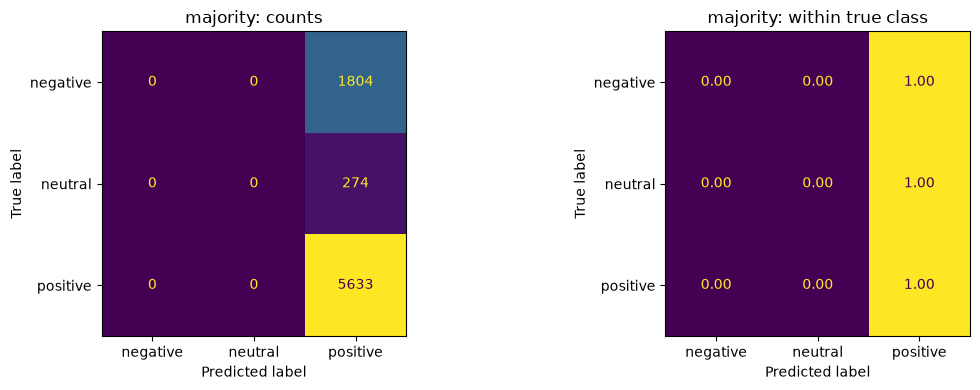

tfidf prediction counts: {'negative': 2158, 'neutral': 615, 'positive': 4938}


,precision,recall,f1-score,support
negative,0.634384,0.758869,0.691065,1804.000000
neutral,0.086179,0.193431,0.119235,274.000000
positive,0.927906,0.813421,0.866900,5633.000000
accuracy,0.778628,0.778628,0.778628,0.778628
macro avg,0.549490,0.588574,0.559067,7711.000000
weighted avg,0.829326,0.778628,0.799196,7711.000000


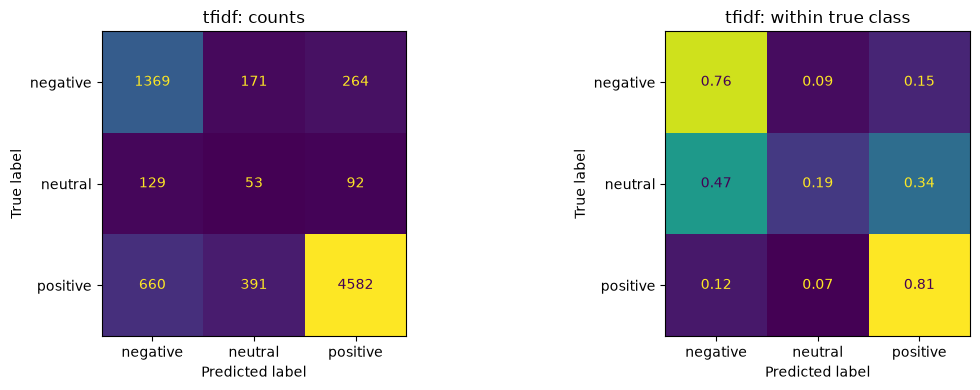

Predicting:   0%|          | 0/7711 [00:00<?, ?batch/s]

xlmr prediction counts: {'negative': 2188, 'neutral': 680, 'positive': 4843}


,precision,recall,f1-score,support
negative,0.648537,0.786585,0.710922,1804.000000
neutral,0.101471,0.251825,0.144654,274.000000
positive,0.944662,0.812178,0.873425,5633.000000
accuracy,0.786279,0.786279,0.786279,0.786279
macro avg,0.564890,0.616863,0.576334,7711.000000
weighted avg,0.845422,0.786279,0.809511,7711.000000


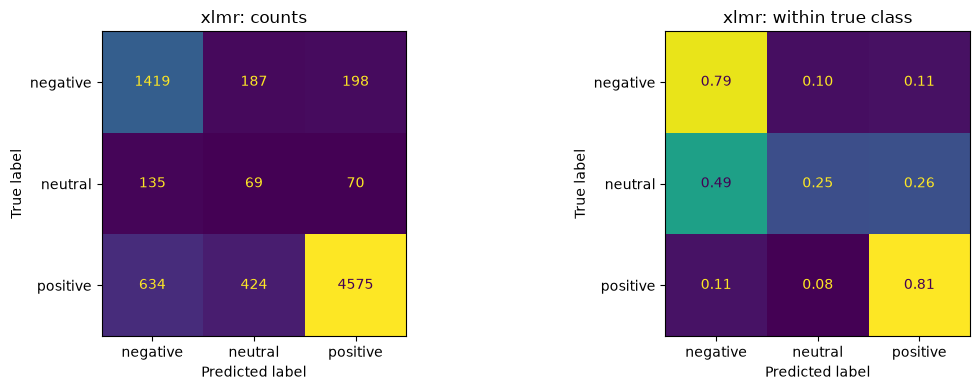

,accuracy,balanced_accuracy,macro_f1,weighted_f1
majority,0.730515,0.333333,0.281425,0.616755
tfidf,0.778628,0.588574,0.559067,0.799196
xlmr,0.786279,0.616863,0.576334,0.809511


In [47]:
test_results = {}
test_predictions = {}
y_test = test_df_sub.sentiment_label.to_numpy()
def report_test(name,pred):
    pred = np.asarray(pred)
    assert len(pred)==len(y_test)
    report = classification_report(y_test,pred,labels=LABELS,output_dict=True,zero_division=0)
    test_results[name] = {'accuracy':accuracy_score(y_test,pred),'balanced_accuracy':balanced_accuracy_score(y_test,pred),'macro_f1':f1_score(y_test,pred,labels=LABELS,average='macro',zero_division=0),'weighted_f1':f1_score(y_test,pred,labels=LABELS,average='weighted',zero_division=0)}
    test_predictions[name] = pred
    pd.DataFrame({'source_row_id':test_df_sub.source_row_id.to_numpy(),'true':y_test,'predicted':pred}).to_csv(OUT/f'{name}_predictions.csv',index=False)
    print(name,'prediction counts:',pd.Series(pred).value_counts().reindex(LABELS,fill_value=0).to_dict())
    display(pd.DataFrame(report).T)
    (OUT/f'{name}_report.json').write_text(json.dumps(report,indent=2))
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    for ax,normalize in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=LABELS,normalize=normalize,ax=ax,colorbar=False,values_format='.2f' if normalize else 'd')
        ax.set_title(f'{name}: '+('within true class' if normalize else 'counts'))
    plt.tight_layout(); plt.savefig(OUT/f'{name}_confusion.png'); plt.show()
report_test('majority',dummy_clf.predict(test_df_sub.text_lexical))
report_test('tfidf',best_model.predict(test_df_sub.text_lexical))
if transformer_model is not None:
    report_test('xlmr',[ID2LABEL[int(i)] for i in predict_transformer(transformer_model,test_dataset)])
else:
    print('No transformer metrics: training was skipped.')
metrics_table = pd.DataFrame(test_results).T
display(metrics_table); metrics_table.to_csv(OUT/'test_metrics.csv')


We read a small sample of mistakes from each true class. This helps distinguish prediction errors from ambiguous wording or a mismatch between text and stars.

In [48]:
for name,pred in test_predictions.items():
    errors = test_df_sub[['content','score','sentiment_label']].copy()
    errors['prediction'] = pred
    errors = errors.loc[errors.sentiment_label.ne(errors.prediction)]
    sample = pd.concat([g.sample(min(5,len(g)),random_state=SEED) for _,g in errors.groupby('sentiment_label')]) if len(errors) else errors
    print(name, 'errors:',len(errors)); display(sample)
    sample.to_csv(OUT/f'{name}_error_review.csv',index=False)
print('Classify these errors as ambiguity, rating mismatch, spelling, negation, code-switching, truncation, or unclear; do not infer a cause from predictions alone.')


majority errors: 2078


,content,score,sentiment_label,prediction
58515,Neçə nəfərik,1,negative,positive
3565,düzgün aparmir bezen,1,negative,positive
30686,Çox pisdi beş saata hərəkət edir. 2saniyede qi...,1,negative,positive
41089,Salam. Sizin taksi xidmətindən istifadə etdiyi...,1,negative,positive
51934,Bu ne cür elan saytidiye elan yerleşdire bilmi...,1,negative,positive
10087,Təşəkkürlər. Düzəldi.,3,neutral,positive
46027,1 aya yaxindi istifade edirdim indi istifade e...,3,neutral,positive
53455,Salam. Qeydiyyatdan keçdikdən bir müddət sonra...,3,neutral,positive
35279,2 gundur program islemir mende nedense,3,neutral,positive
75402,Qatma qarışıqdı yandex bundan 1000dəfə yaxşıdı,3,neutral,positive


tfidf errors: 1707


,content,score,sentiment_label,prediction
49668,Salam Zehmet olmasa yeniliy edin bu yenilik ür...,1,negative,neutral
13927,Sifreni yaziram proqramı guncelemisem yazirki ...,1,negative,neutral
22123,Yaxşı praqramdı isdifadə eləmişəm ama yutubda ...,1,negative,positive
45070,Salam. Satılmış elanı silmәk üçün necә etmәliy...,1,negative,neutral
58017,Kartlar arası əməliyyatlar ödənişsiz olsa lap ...,2,negative,neutral
46279,Kartima pul atirlar gelmir gerey proqrami sile...,3,neutral,negative
51262,Bir kopuklukdu,3,neutral,negative
33691,Men bu proqramin ne ise yaradigini anliya bilm...,3,neutral,positive
62515,men hemise maas kartimla birbankda bawqa kartm...,3,neutral,positive
7185,"Giriş etmək istəyirəm, telefona kod gəlir yazı...",3,neutral,negative


xlmr errors: 1648


,content,score,sentiment_label,prediction
52864,Salam her vaxtiniz xeyir zehmet olmasa men bir...,1,negative,neutral
50245,Belə yaxşıdı,1,negative,positive
71287,"Müasir,bütün tələblərə cavab verən taksi xidmə...",1,negative,positive
65961,gedis gelis cox superdi bu axir vaxdlar kartna...,1,negative,positive
12213,Salam nömrəmi yazıtam məni tapır amma kod gəlm...,1,negative,neutral
7310,bfd,3,neutral,positive
6222,Hələki köhnə app.la idarə edirik.Mıya da şükür.,3,neutral,positive
35730,Salam. Hər dəfə praqrama giriş etdikdə gərək t...,3,neutral,negative
46604,"Elani pulsuz qaldirmaq mumkun olsun ,tək catiş...",3,neutral,negative
27304,Qorxulu melim,3,neutral,positive


Classify these errors as ambiguity, rating mismatch, spelling, negation, code-switching, truncation, or unclear; do not infer a cause from predictions alone.


# Prepare text for topic modeling

Require at least three retained tokens for thematic analysis. Short reviews remain in sentiment classification; topic coverage is reported separately.

We build a Gensim dictionary and word-count representation for LDA using training texts only. Vocabulary filtering reduces rare terms, while coverage checks reveal how much text is excluded.

In [49]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from collections import Counter
TOPIC_SAMPLE = 12000
STOPWORDS = set('və ve ilə ile üçün ucun bu bir o da də de ki mən men sən sen biz siz onlar salam'.split())
def topic_tokens(text):
    return [w for w in re.findall(r'[^\W\d_]+',az_lowercase(text)) if len(w)>1 and w not in STOPWORDS]
topic_frame = df_all.loc[df_all.partition.eq('train')].sample(n=min(TOPIC_SAMPLE,len(df_train_full)),random_state=SEED).copy()
topic_frame['tokens'] = topic_frame.text_transformer.map(topic_tokens)
MIN_TOPIC_TOKENS = 3
print('Training texts below thematic length threshold:',int(topic_frame.tokens.map(len).lt(MIN_TOPIC_TOKENS).sum()))
topic_frame = topic_frame.loc[topic_frame.tokens.map(len).ge(MIN_TOPIC_TOKENS)].copy()
assert topic_frame.norm_key.is_unique
display(topic_frame[['content','tokens']].head(8))
print('Frequent retained tokens:',Counter(w for row in topic_frame.tokens for w in row).most_common(30))
dictionary = Dictionary(topic_frame.tokens)
before_vocab = len(dictionary)
dictionary.filter_extremes(no_below=5,no_above=0.6,keep_n=15000)
corpus = [dictionary.doc2bow(t) for t in topic_frame.tokens]
print('Vocabulary before/after filtering:',before_vocab,len(dictionary))
print('Empty training bags:',sum(not b for b in corpus),'/',len(corpus))
corpus = [b for b in corpus if b]
assert len(dictionary)>20 and len(corpus)>100, 'Insufficient vocabulary: inspect preprocessing.'
validation_topics = val_df_sub.sample(min(3000,len(val_df_sub)),random_state=SEED)
val_corpus = [dictionary.doc2bow(topic_tokens(t)) for t in validation_topics.text_transformer if len(topic_tokens(t))>=MIN_TOPIC_TOKENS]
val_corpus = [b for b in val_corpus if b]
assert val_corpus, 'No usable validation bags.'


Training texts below thematic length threshold: 2788


,content,tokens
50805,cox razi qaldim twk ler,"[cox, razi, qaldim, twk, ler]"
11171,Rayonan ev telfonuyla yigmaq odenislidi?,"[rayonan, ev, telfonuyla, yigmaq, odenislidi]"
38095,Bolt xidməti çox pisdi adamı aldadıb pulun qay...,"[bolt, xidməti, çox, pisdi, adamı, aldadıb, pu..."
50970,Cindir şöferleri olmasa yaxşıdir,"[cindir, şöferleri, olmasa, yaxşıdir]"
3580,Hər şey mənə görə mükəmməldir,"[hər, şey, mənə, görə, mükəmməldir]"
53244,Qiymet önəmli olsa da xidmət önde gəlir,"[qiymet, önəmli, olsa, xidmət, önde, gəlir]"
51659,Men sizin mobil tetbiqinizi yukledim ancaq kar...,"[sizin, mobil, tetbiqinizi, yukledim, ancaq, k..."
56725,Eladi ve cox rahatdi ama bezi catismazliqlar v...,"[eladi, cox, rahatdi, ama, bezi, catismazliqla..."


Frequent retained tokens: [('çox', 1923), ('cox', 1094), ('əla', 729), ('olar', 653), ('super', 613), ('amma', 579), ('yaxşı', 541), ('gözəl', 500), ('olmur', 483), ('edirəm', 464), ('var', 440), ('hər', 385), ('ela', 379), ('pul', 371), ('ama', 370), ('proqram', 360), ('olur', 347), ('pis', 329), ('nə', 315), ('daha', 310), ('olsun', 306), ('rahat', 299), ('bank', 283), ('edirem', 280), ('her', 271), ('tez', 268), ('olmasa', 267), ('ne', 260), ('gozel', 253), ('kimi', 251)]
Vocabulary before/after filtering: 20184 2374
Empty training bags: 76 / 9212


# Find and interpret topics

Compare topic counts, inspect distinct examples and check a second random seed. Topic names are provisional; changed keyword signatures require a new interpretation.

We compare LDA models with 5, 8 and 12 topics using validation coherence, then inspect keywords and example reviews. We also match topics across two random seeds by keyword overlap to check stability.

In [50]:
topic_candidates = []
for k in tqdm([5,8,12],desc='Fitting LDA candidates'):
    model = LdaModel(corpus=corpus,id2word=dictionary,num_topics=k,passes=5,iterations=60,random_state=SEED,alpha='auto',minimum_probability=0.0)
    coherence = CoherenceModel(model=model,corpus=val_corpus,dictionary=dictionary,coherence='u_mass').get_coherence()
    topic_candidates.append((coherence,k,model))
display(pd.DataFrame([(s,k) for s,k,_ in topic_candidates],columns=['validation_umass','topics']))
_,K,lda = max(topic_candidates,key=lambda x:x[0])
lda.save(str(OUT/'topics.lda')); dictionary.save(str(OUT/'topic_dictionary.gensim'))
def topic_matrix(frame):
    bags = [dictionary.doc2bow(topic_tokens(t)) for t in frame.text_transformer]
    covered = np.array([bool(b) and len(topic_tokens(t))>=MIN_TOPIC_TOKENS for b,t in zip(bags,frame.text_transformer)])
    matrix = np.array([[p for _,p in lda.get_document_topics(b,minimum_probability=0.0)] for b,keep in zip(bags,covered) if keep])
    return frame.loc[covered].reset_index(drop=True),matrix,covered
covered_train,train_topics,_ = topic_matrix(topic_frame)
interpretations = []
for k in range(K):
    words = ', '.join(w for w,_ in lda.show_topic(k,12))
    indices = np.argsort(train_topics[:,k])[-5:][::-1]
    print('\nTOPIC',k,words)
    row = {'topic':k,'keywords':words,'provisional_name':'Unreviewed topic '+str(k),'interpretation':'Inspect the distinct examples before naming this topic.','annotation_source':'pending review'}
    for rank,i in enumerate(indices,1):
        text = covered_train.iloc[i].content
        row[f'example_{rank}'] = text
        print(f'[{train_topics[i,k]:.2f}; {covered_train.iloc[i].score} stars]',text)
    interpretations.append(row)
interpretation_path = OUT/'topic_interpretation.csv'
if not interpretation_path.exists(): pd.DataFrame(interpretations).to_csv(interpretation_path,index=False)
else: print('Existing interpretation worksheet preserved; compare its topic IDs with this run before reuse.')
second_seed = LdaModel(corpus=corpus,id2word=dictionary,num_topics=K,passes=5,iterations=60,random_state=SEED+1,alpha='auto')
print('Second-seed keywords for qualitative stability inspection:')
for k in range(K): print(k,second_seed.show_topic(k,10))
from scipy.optimize import linear_sum_assignment
word_sets = [set(w for w,_ in lda.show_topic(k,10)) for k in range(K)]
other_sets = [set(w for w,_ in second_seed.show_topic(k,10)) for k in range(K)]
similarity = np.array([[len(a&b)/len(a|b) for b in other_sets] for a in word_sets])
left,right = linear_sum_assignment(-similarity)
stability = pd.DataFrame({'topic':left,'matched_second_seed_topic':right,'top10_jaccard':similarity[left,right]})
display(stability)
stability.to_csv(OUT/'topic_stability.csv',index=False)
print('Mean matched keyword overlap:',stability.top10_jaccard.mean())
print('Overlap is a diagnostic, not a universal pass/fail criterion.')


Fitting LDA candidates:   0%|          | 0/3 [00:00<?, ?it/s]

,validation_umass,topics
0,-7.005795,5
1,-9.020922,8
2,-10.849342,12



TOPIC 0 cox, edirem, nece, ne, her, bilmirem, bele, ama, niye, pul, ela, var
[0.98; 1 stars] Bu bir ulduzda coxdu Salam Bu gun taksi sifaris verdim sagolun taksi gonderdiz amma onu deyim ki xidmet cox sifirdir. Niye onuda deyim teze yukledim boltu promo kod verdi istifade edib taksi sifaris eledim taski soferi promo kodu tekzib eledi ve dediki bu qiymet serf elemir men yolda qalmamaq ucun mecbur getdim 3 manat pul verdim. Bele biyabirciliq olar olmaz bilmir. Amma besdirin az aldatdiz camaati Yeqin ki tenqide aciq olarsiz.
[0.96; 1 stars] cox pis. Surucu zeng eliyib sifariwi legv elemeyi teleb eliyir ve kartla sifaris edende adama ele minnet qoyurlarki Serf elemir iwleme. Bele getse silecem boltu
[0.95; 5 stars] Salam men Bir kart elde etmek ucun ne etmeliyem mende kapital bank karti yoxdu is yerim yoxdu kart sifarisi nece azn dir
[0.95; 1 stars] 03.05.23 tarixinde rey yazmiwdim ama bugun reyi deyiwirem.guncelledim praqrami nomre itdi bonus itdi nem tezden kod isteyir soxasan bele tedb

,topic,matched_second_seed_topic,top10_jaccard
0,0,3,0.333333
1,1,2,0.176471
2,2,0,1.000000
3,3,4,0.176471
4,4,1,0.250000


Mean matched keyword overlap: 0.3872549019607843
Overlap is a diagnostic, not a universal pass/fail criterion.


We add provisional topic names based on reviewed keywords and examples. A name is reused only when its keyword signature matches, avoiding stale labels after a model change.

In [51]:
REVIEWED_TOPICS = {'cox, edirem, nece, ne, her, bilmirem, bele, ama, niye, pul, ela, var': {'provisional_name': 'Mixed informal complaints and help requests', 'interpretation': 'Taxi fare/driver complaints, bank-card questions and update issues appear together. Informal spellings are prominent; this is not a single well-separated business theme.'}, 'olmur, olmasa, daxil, nə, bilmirəm, amma, tez, işləmir, verir, niyə, qeydiyyatdan, sonra': {'provisional_name': 'Login, registration and app failures', 'interpretation': 'Four leading examples describe blocked access, registration failures or crashes; another concerns payment restrictions. Treat access failures as the central theme, with some transaction overlap.'}, 'çox, əla, gözəl, hər, edirəm, super, yaxşı, olsun, proqramdır, rahat, allah, şey': {'provisional_name': 'Convenience, useful features and praise', 'interpretation': 'Examples praise balance management, online utility payments, time savings, accessible tariff controls and bonuses. Some also request extra features; praise does not mean the absence of requests.'}, 'kapital, kart, heç, kimi, pul, sizin, sifariş, yox, belə, bank, manat, gün': {'provisional_name': 'Mixed payment, order and service problems', 'interpretation': 'Examples concern driver/order handling, delivery availability, stale balances and transfers. Mixed operational complaints; do not present it as a narrowly defined banking topic.'}, 'olar, cox, ela, olsa, daha, yaxşı, necə, super, amma, gozel, yaxsi, ama': {'provisional_name': 'Feature requests and qualified praise', 'interpretation': 'Users ask for separate new/used listings, updated maps, data/bonus packages and gifts. Praise is frequently qualified by a requested improvement.'}}
reviewed_topics = pd.DataFrame(interpretations)
for i,row in reviewed_topics.iterrows():
    note = REVIEWED_TOPICS.get(row['keywords'])
    if note:
        reviewed_topics.loc[i,'provisional_name'] = note['provisional_name']
        reviewed_topics.loc[i,'interpretation'] = note['interpretation']
        reviewed_topics.loc[i,'annotation_source'] = 'assistant review of keywords and five distinct examples; provisional'
reviewed_topics.to_csv(OUT/'topic_interpretation.csv',index=False)
display(reviewed_topics[['topic','provisional_name','interpretation','annotation_source']])


,topic,provisional_name,interpretation,annotation_source
0,0,Mixed informal complaints and help requests,"Taxi fare/driver complaints, bank-card questio...",assistant review of keywords and five distinct...
1,1,"Login, registration and app failures","Four leading examples describe blocked access,...",assistant review of keywords and five distinct...
2,2,"Convenience, useful features and praise","Examples praise balance management, online uti...",assistant review of keywords and five distinct...
3,3,"Mixed payment, order and service problems","Examples concern driver/order handling, delive...",assistant review of keywords and five distinct...
4,4,Feature requests and qualified praise,"Users ask for separate new/used listings, upda...",assistant review of keywords and five distinct...


# Compare topics by sentiment

Values are average topic probabilities among covered texts, not percentages assigned to one issue. Positive-rated reviews can still contain complaints.

We apply one shared topic model to every sentiment group and compare average topic probabilities. Separate coverage figures show which reviews contribute to those comparisons.

,rows,vocabulary_coverage,length_eligible,topic_coverage,covered_rows
sentiment_label,,,,,
negative,1804,0.964523,0.923503,0.917960,1656
neutral,274,0.923358,0.886861,0.879562,241
positive,5633,0.883366,0.717202,0.709924,3999


,0,1,2,3,4
sentiment,,,,,
negative,0.234536,0.309056,0.176898,0.164924,0.114586
neutral,0.188364,0.315841,0.199468,0.149250,0.147078
positive,0.207653,0.145364,0.374048,0.096289,0.176646


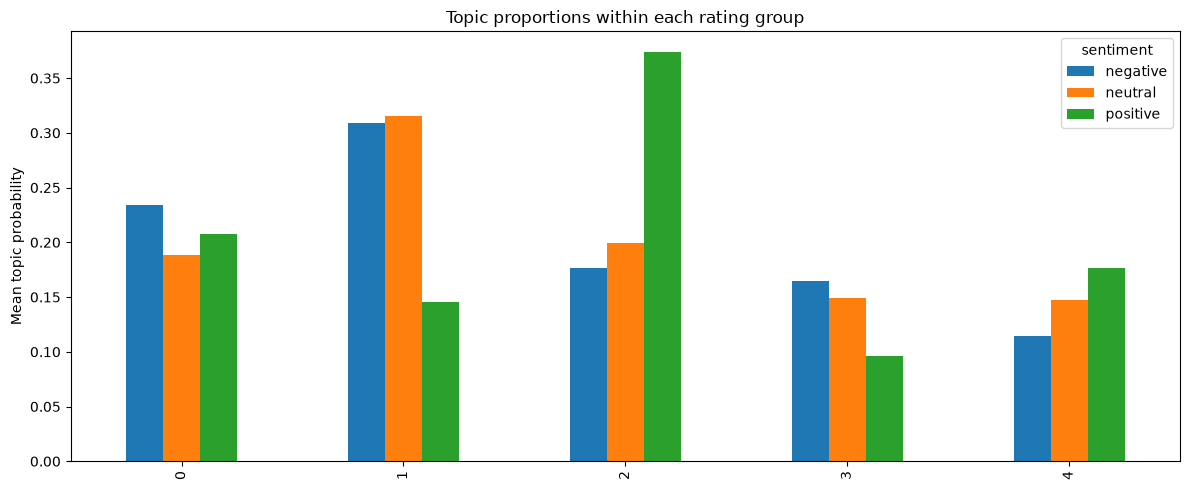

,topic,keywords,negative,positive,negative_minus_positive
1,1,"olmur, olmasa, daxil, nə, bilmirəm, amma, tez,...",0.309056,0.145364,0.163692
3,3,"kapital, kart, heç, kimi, pul, sizin, sifariş,...",0.164924,0.096289,0.068635
0,0,"cox, edirem, nece, ne, her, bilmirem, bele, ama",0.234536,0.207653,0.026883
4,4,"olar, cox, ela, olsa, daha, yaxşı, necə, super",0.114586,0.176646,-0.062060
2,2,"çox, əla, gözəl, hər, edirəm, super, yaxşı, olsun",0.176898,0.374048,-0.197150


Topic 2 negative
çox gözəl programdı. işləri daha rahat və sadə şəkildə həll etmək mümkündü
Umico marketi bəyənirəm umiconun xidmətlərindən çox razıyam. Əladır
Topic 2 positive
Əladı kim bunu ərsəyə gətiribsə Allah balasın saxlasın və bizə xidmət görsədən sürücülərimizidə ALLAH xətadan bəladan uzağ eləsin Gündüz ruzilərin qazanıb gecə evdərinə sağ salamat qayıtmağı arzulayıram Uca Rəbbim hamınızı qorusun inşAllah AMİN
Çox əladır bunu bizim evdə hər kəs yükləyib və çox gözəldi təşəkkürlər 👍👍
Topic 1 negative
Ədv geri almaqçün qr kodu vurram keçmir şeklində qalareyadan köçürrəm yenədə açmır niyə? Son günlər belə olub
Mən neçə gündü Birbanka giriş edə bilmirəm, səbəb nədir, zəhmət olmasa cavablandırın
Topic 1 positive
Salam bir bank praqramində qr kod oxunmur qeydiyyatdan kec deyir kecmisəm qeydiyyatda ola ola yenə qeydiyatdan kec deyir necə edinki qr kodu gostərənde edv yuklənsin
Salam mən necə edə bilərəmki,çek vurduqda ədv üçün qeydiyyatdan keşməyim. Çeki göndərim və karta düşsün? Zəhm

In [52]:
covered_test,topic_probs,coverage = topic_matrix(test_df_sub)
coverage_details = test_df_sub.assign(has_vocabulary=[bool(dictionary.doc2bow(topic_tokens(t))) for t in test_df_sub.text_transformer],enough_tokens=[len(topic_tokens(t))>=MIN_TOPIC_TOKENS for t in test_df_sub.text_transformer],topic_covered=coverage)
coverage_table = coverage_details.groupby('sentiment_label').agg(rows=('topic_covered','size'),vocabulary_coverage=('has_vocabulary','mean'),length_eligible=('enough_tokens','mean'),topic_coverage=('topic_covered','mean'),covered_rows=('topic_covered','sum'))
display(coverage_table); coverage_table.to_csv(OUT/'topic_coverage.csv')
shares = pd.DataFrame(topic_probs,columns=range(K)).assign(sentiment=covered_test.sentiment_label).groupby('sentiment').mean().reindex(LABELS)
display(shares)
shares.T.plot.bar(figsize=(12,5),ylabel='Mean topic probability',title='Topic proportions within each rating group')
plt.tight_layout(); plt.savefig(OUT/'topics_by_sentiment.png'); plt.show()
comparison = pd.DataFrame({'topic':range(K),'keywords':[', '.join(w for w,_ in lda.show_topic(k,8)) for k in range(K)],'negative':shares.loc['negative'].values,'positive':shares.loc['positive'].values})
comparison['negative_minus_positive'] = comparison.negative-comparison.positive
display(comparison.sort_values('negative_minus_positive',ascending=False))
comparison.to_csv(OUT/'topic_comparison.csv',index=False)

for k in comparison.reindex(comparison.negative_minus_positive.abs().sort_values(ascending=False).index).head(3).topic:
    for sentiment in ['negative','positive']:
        eligible = np.flatnonzero(covered_test.sentiment_label.eq(sentiment).to_numpy())
        selected = eligible[np.argsort(topic_probs[eligible,k])[-2:][::-1]]
        print('Topic',k,sentiment)
        for i in selected: print(covered_test.iloc[i].content)


# Summarize results

Scores measure agreement with rating-derived labels. Interpret the findings within the distinct-text evaluation population and the reported topic coverage.

We collect the measured results and save package versions, data hashes and model settings. These records support reproduction and keep conclusions tied to the actual run.

In [53]:
print('Measured test results:'); display(metrics_table)
print('Baseline macro-F1 improvement over majority:',test_results['tfidf']['macro_f1']-test_results['majority']['macro_f1'])
if 'xlmr' in test_results:
    print('Transformer minus baseline macro-F1:',test_results['xlmr']['macro_f1']-test_results['tfidf']['macro_f1'])
else:
    print('Transformer comparison unavailable: training not executed.')
versions = {}
for package in ['numpy','pandas','scikit-learn','torch','transformers','datasets','gensim','matplotlib']:
    try: versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: versions[package] = 'not installed'
metadata = {'seed':SEED,'versions':versions,'model':MODEL_NAME if RUN_TRANSFORMER else 'xlm-roberta-base','transformer_trained_this_run':transformer_model is not None,'train_rows':len(train_df_sub),'validation_rows':len(val_df_sub),'test_rows':len(test_df_sub),'max_length':128,'epochs':EPOCHS,'batch_size':BATCH_SIZE,'gradient_accumulation':ACCUMULATION,'learning_rate':LR,'topic_count':K,'source_sha256':{name:hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in ['train.csv','test.csv']}}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
train_df_sub[['source_row_id','norm_key','sentiment_label','original_split']].to_csv(OUT/'actual_training_rows.csv',index=False)
print('Artifacts saved to',OUT.resolve())
metadata['partition_policy'] = config_metadata
metadata['topic_min_tokens'] = MIN_TOPIC_TOKENS
metadata['loss'] = 'class-weighted per-example cross entropy, arithmetic mean; preserves weights with batch size 1'
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
for model_name,predictions in test_predictions.items():
    neutral = y_test=='neutral'
    print(model_name,'neutral recall:',float(np.mean(np.asarray(predictions)[neutral]=='neutral')))
print('Interpret all scores as agreement with rating-derived labels on distinct non-conflicting texts.')


Measured test results:


,accuracy,balanced_accuracy,macro_f1,weighted_f1
majority,0.730515,0.333333,0.281425,0.616755
tfidf,0.778628,0.588574,0.559067,0.799196
xlmr,0.786279,0.616863,0.576334,0.809511


Baseline macro-F1 improvement over majority: 0.277641881121372
Transformer minus baseline macro-F1: 0.017266893133652483
Artifacts saved to /home/omar/Documents/devlab/week7/artifacts_corrected/20261102T200542515178Z
majority neutral recall: 0.0
tfidf neutral recall: 0.19343065693430658
xlmr neutral recall: 0.2518248175182482
Interpret all scores as agreement with rating-derived labels on distinct non-conflicting texts.


## Results at a glance

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| Majority | 73.05% | 0.2814 |
| TF-IDF | 77.86% | 0.5591 |
| XLM-R | **78.63%** | **0.5763** |

XLM-R improved modestly over TF-IDF. Epoch 2 was selected; neutral recall was 25.18% (69 of 274 reviews).

Topics highlight access failures, payment/service issues, convenience and feature requests. Some topics remain mixed or unstable across seeds.

Results apply to distinct, non-conflicting texts. Rating noise, weak neutral performance and unequal topic coverage remain limitations.